# CS781 Phase 3. Encoder-decoder LoRA for rhetorical role prediction

I froze the Phase 1 encoder-decoder and added rank-32 LoRA to attention and feed-forward projections in both stacks. Both stacks read the known sentence chunk. The task head mean-pools decoder content states and decodes roles across the document.

| Run | Best epoch | Epochs completed | Dev macro F1 | CodaBench macro F1 | Submission ID |
| --- | ---: | ---: | ---: | ---: | ---: |
| Encoder-decoder LoRA | 21 | 29 | 0.4314 | 0.4015 | 990705 |


## 1. Inputs and environment

1. Start a Kaggle session with two T4 GPUs. Use the session's PyTorch installation.
2. Attach `prep_002_mixed16k` with its tokenizer and manifest. Attach the original
   [Phase 1 run](../phase1/phase1_encoder_decoder_training.ipynb) `encdec_002_mixed217m_stable` with `best_model.pt`
   and its source files. Set `PREP_INPUT` and `ENCDEC_INPUT` if automatic
   discovery is ambiguous.
3. Set `RR_DATA_INPUT` to the official data folder if it is already available.
   For the pinned download, enable Internet and provide the Kaggle secret `HF_TOKEN`.
4. Run the [encoder-decoder preflight](phase3_encoder_decoder_lora_preflight.ipynb) in the same working session, or
   attach `encdec_rr_lora_preflight_001_diagnostics.zip` and set `PREFLIGHT_INPUT`. Use
   `RESUME_INPUT` to restore a matching training backup.


In [1]:
%pip install -q huggingface_hub pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import hashlib
import importlib.metadata
import json
import math
from pathlib import Path
import random
import shutil
import sys
import time

import numpy as np
import pandas as pd
import torch
from IPython.display import display

RUN_ID='encdec_rr_lora_001'
PREP_INPUT=None
ENCDEC_INPUT=None
RR_DATA_INPUT=None
PREFLIGHT_INPUT=None
RESUME_INPUT=None

ROOT=Path('/kaggle/working/cs781_phase3')
SRC=Path('/kaggle/working/cs781_phase3_encdec_rr_src')
RUN_DIR=ROOT/'runs'/RUN_ID
for folder in (ROOT,SRC,RUN_DIR):
    folder.mkdir(parents=True,exist_ok=True)

RUN_TRAINING=True
TRAIN_MAX_UPDATES_THIS_INVOCATION=None  # Optional deliberate pause after completed optimizer updates.
SETTINGS={
    'seed':42,'window_sentences':128,'overlap_sentences':32,
    'chunk_tokens':256,'chunk_microbatch':16,'global_window_batch':2,'accumulation_steps':2,
    'gradient_checkpointing':True,'projection_dim':256,'context_hidden':128,'head_dropout':0.20,
    'lora_rank':32,'lora_alpha':64,'lora_dropout':0.05,'lora_lr':2e-4,
    'head_lr':3e-4,'crf_lr':1e-3,'weight_decay':0.01,'gradient_clip':1.0,
    'class_weight_cap':5.0,'aux_ce_coefficient':0.5,'require_two_gpus':True,
    'epochs':35,'minimum_epochs':15,'patience':8,'early_stop_min_delta':1e-4,
    'warmup_fraction':0.05,'minimum_lr_fraction':0.01,
    'train_metrics_every_epochs':3,'dev_metrics_every_epochs':1,
    'max_run_hours':9.0,'save_every_minutes':3.0,'log_every_updates':10,'backup_on_save':True,
}
torch.set_num_threads(2)
random.seed(SETTINGS['seed'])
np.random.seed(SETTINGS['seed'])
torch.manual_seed(SETTINGS['seed'])
if not torch.cuda.is_available() or torch.cuda.device_count()<2:
    raise RuntimeError('Select Kaggle T4 x2 for the agreed configuration.')
if any(torch.cuda.memory_allocated(i)>256*2**20 for i in range(2)):
    raise RuntimeError('Restart the kernel before running this notebook; another model is still allocated.')
torch.cuda.manual_seed_all(SETTINGS['seed'])
print('Run:',RUN_ID,'| GPUs:',[torch.cuda.get_device_name(i) for i in range(2)])
print('Working disk free GiB:',round(shutil.disk_usage(ROOT).free/2**30,2))

Run: encdec_rr_lora_001 | GPUs: ['Tesla T4', 'Tesla T4']
Working disk free GiB: 19.48


## 2. Implementation

These cells write the original Phase 1 tokenizer and backbone, data preparation, role model, training helpers and course evaluator into the Kaggle working directory. The run checks these sources against its saved provenance.


In [3]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path


Writing /kaggle/working/cs781_phase3_encdec_rr_src/phase1_utils.py


In [4]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Writing /kaggle/working/cs781_phase3_encdec_rr_src/a1_tokenizer.py


In [5]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/architecture_models.py
"""Three from-scratch Phase 1 Transformers; course blocks with cited extensions.

SDPA Boolean masks use True for ALLOWED connections. All blocks are pre-norm.
Training uses full teacher-forced sequences. KV caches are inference-only.
"""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    architecture: str = "encoder_decoder"
    vocab_size: int = 16000
    d_model: int = 1024
    n_heads: int = 16
    n_layers: int = 16
    encoder_layers: int = 8
    decoder_layers: int = 6
    n_kv_heads: int = 4
    d_ff: int = 4096
    max_seq_len: int = 2560
    dropout: float = 0.1
    window_size: int = 512
    query_chunk_size: int = 128


def configuration(architecture):
    if architecture not in ("encoder_decoder", "prefix", "efficient"):
        raise ValueError("Unknown architecture")
    return ModelConfig(architecture=architecture, d_ff=4864 if architecture == "efficient" else 4096)


def positions(max_len, width):
    p = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, width, 2).float() * (-math.log(10000.0) / width))
    result = torch.zeros(max_len, width)
    result[:, 0::2] = torch.sin(p * frequency)
    result[:, 1::2] = torch.cos(p * frequency)
    return result


def valid_keys(lengths, width):
    return torch.arange(width, device=lengths.device)[None, :] < lengths[:, None]


class Attention(nn.Module):
    def __init__(self, cfg, kv_heads=None):
        super().__init__()
        self.heads = cfg.n_heads
        self.kv_heads = cfg.n_heads if kv_heads is None else kv_heads
        assert cfg.d_model % self.heads == 0 and self.heads % self.kv_heads == 0
        self.head_dim = cfg.d_model // self.heads
        self.q_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.dropout = cfg.dropout
        self.resid_dropout = nn.Dropout(cfg.dropout)

    def query(self, x):
        b, t, _ = x.shape
        return self.q_proj(x).view(b, t, self.heads, self.head_dim).transpose(1, 2)

    def keys_values(self, x):
        b, t, _ = x.shape
        k = self.k_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        return k, v

    def attend(self, q, k, v, allowed=None, causal=False):
        # A3 Q2: repeat each KV head for its group of query heads.
        if self.kv_heads != self.heads:
            repeats = self.heads // self.kv_heads
            k, v = k.repeat_interleave(repeats, dim=1), v.repeat_interleave(repeats, dim=1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, is_causal=causal,
            dropout_p=self.dropout if self.training else 0.0, scale=1 / math.sqrt(self.head_dim))
        b, _, t, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(b, t, -1)
        return self.resid_dropout(self.out_proj(out))

    def forward(self, x, memory=None, allowed=None, causal=False):
        k, v = self.keys_values(x if memory is None else memory)
        return self.attend(self.query(x), k, v, allowed, causal)

    def local(self, x, window, chunk, lengths=None):
        # Query tiles see only nearby keys. No full T-by-T score matrix.
        q = self.query(x)
        k, v = self.keys_values(x)
        t = x.shape[1]
        pieces = []
        for start in range(0, t, chunk):
            stop = min(t, start + chunk)
            first = max(0, start - window + 1)
            qi = torch.arange(start, stop, device=x.device)
            ki = torch.arange(first, stop, device=x.device)
            allowed = (ki[None, :] <= qi[:, None]) & (ki[None, :] > qi[:, None] - window)
            allowed = allowed[None, None, :, :]
            if lengths is not None:
                allowed = allowed & (ki[None, :] < lengths[:, None])[:, None, None, :]
            pieces.append(self.attend(q[:, :, start:stop], k[:, :, first:stop], v[:, :, first:stop], allowed))
        return torch.cat(pieces, dim=1)


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(cfg.d_model, cfg.d_ff), nn.GELU(),
                                 nn.Linear(cfg.d_ff, cfg.d_model), nn.Dropout(cfg.dropout))

    def forward(self, x):
        return self.net(x)


class EncoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg), FeedForward(cfg)

    def forward(self, x, allowed):
        x = x + self.attn(self.ln1(x), allowed=allowed)
        return x + self.ffn(self.ln2(x))


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2, self.ln3 = (nn.LayerNorm(cfg.d_model) for _ in range(3))
        self.self_attn, self.cross_attn, self.ffn = Attention(cfg), Attention(cfg), FeedForward(cfg)

    def forward(self, x, memory, allowed):
        x = x + self.self_attn(self.ln1(x), causal=True)
        x = x + self.cross_attn(self.ln2(x), memory=memory, allowed=allowed)
        return x + self.ffn(self.ln3(x))


class PrefixBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg), FeedForward(cfg)

    def forward(self, prompt, decoder, prefix_allowed):
        # The prompt cannot see decoder tokens; decoder queries see both parts.
        p = self.ln1(prompt)
        d = self.ln1(decoder)
        pk, pv = self.attn.keys_values(p)
        dk, dv = self.attn.keys_values(d)
        prompt = prompt + self.attn.attend(self.attn.query(p), pk, pv, prefix_allowed)
        t = decoder.shape[1]
        triangular = torch.ones(t, t, dtype=torch.bool, device=decoder.device).tril()
        allowed = torch.cat([prefix_allowed.expand(-1, -1, t, -1),
                             triangular[None, None].expand(decoder.shape[0], 1, -1, -1)], dim=-1)
        decoder = decoder + self.attn.attend(self.attn.query(d), torch.cat([pk, dk], dim=2),
                                            torch.cat([pv, dv], dim=2), allowed)
        return prompt + self.ffn(self.ln2(prompt)), decoder + self.ffn(self.ln2(decoder))


class EfficientBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg, cfg.n_kv_heads), FeedForward(cfg)
        self.window, self.chunk = cfg.window_size, cfg.query_chunk_size

    def forward(self, x, lengths=None):
        x = x + self.attn.local(self.ln1(x), self.window, self.chunk, lengths)
        return x + self.ffn(self.ln2(x))


class BaseModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", positions(cfg.max_seq_len, cfg.d_model), persistent=False)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def initialize(self):
        for p in self.parameters():
            if p.ndim > 1:
                nn.init.xavier_uniform_(p)
        for m in self.modules():
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def embed(self, ids, offset=None, role=None):
        t = ids.shape[1]
        p = torch.arange(t, device=ids.device)[None, :]
        if offset is not None:
            p = p + offset[:, None]
        x = self.tok_emb(ids) * math.sqrt(self.cfg.d_model) + self.pos_emb[p]
        if role is not None:
            x = x + self.segment_emb.weight[role]
        return x


class EncoderDecoderLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.encoder = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg.encoder_layers)])
        self.decoder = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg.decoder_layers)])
        self.encoder_norm, self.decoder_norm = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.initialize()

    def encode(self, prompt, lengths):
        allowed = valid_keys(lengths, prompt.shape[1])[:, None, None, :]
        x = self.embed(prompt)
        for block in self.encoder:
            x = block(x, allowed)
        return self.encoder_norm(x), allowed

    def forward(self, prompt, decoder_ids, lengths=None):
        if prompt.shape[1] + decoder_ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Prompt plus decoder exceeds context budget")
        if lengths is None:
            lengths = torch.full((prompt.shape[0],), prompt.shape[1], device=prompt.device, dtype=torch.long)
        memory, allowed = self.encode(prompt, lengths)
        x = self.embed(decoder_ids)
        for block in self.decoder:
            x = block(x, memory, allowed)
        return self.head(self.decoder_norm(x))

    def start_generation(self, prompt, lengths):
        memory, allowed = self.encode(prompt, lengths)
        layers = []
        for block in self.decoder:
            k, v = block.cross_attn.keys_values(memory)
            layers.append({"cross_k": k, "cross_v": v,
                           "k": k[:, :, :0], "v": v[:, :, :0]})
        cache = {"layers": layers, "allowed": allowed, "lengths": lengths,
                 "decoder_position": 0, "next_positions": lengths.clone()}
        bos = torch.full((prompt.shape[0], 1), 2, dtype=torch.long, device=prompt.device)
        return self.generation_step(bos, cache)

    def generation_step(self, ids, cache):
        position = cache["decoder_position"]
        x = self.embed(ids, offset=torch.full_like(cache["lengths"], position))
        for block, layer in zip(self.decoder, cache["layers"]):
            h = block.ln1(x)
            k, v = block.self_attn.keys_values(h)
            layer["k"], layer["v"] = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            # One new query may see all cached decoder keys, including itself.
            x = x + block.self_attn.attend(block.self_attn.query(h), layer["k"], layer["v"])
            x = x + block.cross_attn.attend(block.cross_attn.query(block.ln2(x)),
                                          layer["cross_k"], layer["cross_v"], cache["allowed"])
            x = x + block.ffn(block.ln3(x))
        cache["decoder_position"] += 1
        cache["next_positions"] = cache["lengths"] + cache["decoder_position"]
        return self.head(self.decoder_norm(x))[:, -1], cache


class PrefixLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.segment_emb = nn.Embedding(2, cfg.d_model)
        self.blocks = nn.ModuleList([PrefixBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.d_model)
        self.initialize()

    def forward(self, prompt, decoder_ids, lengths=None):
        if prompt.shape[1] + decoder_ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Prompt plus decoder exceeds context budget")
        if lengths is None:
            lengths = torch.full((prompt.shape[0],), prompt.shape[1], device=prompt.device, dtype=torch.long)
        allowed = valid_keys(lengths, prompt.shape[1])[:, None, None, :]
        p, d = self.embed(prompt, role=0), self.embed(decoder_ids, offset=lengths, role=1)
        for block in self.blocks:
            p, d = block(p, d, allowed)
        return self.head(self.final_norm(d))

    def start_generation(self, prompt, lengths):
        allowed = valid_keys(lengths, prompt.shape[1])[:, None, None, :]
        x = self.embed(prompt, role=0)
        layers = []
        for block in self.blocks:
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            layers.append({"prefix_k": k, "prefix_v": v, "k": k[:, :, :0], "v": v[:, :, :0]})
            x = x + block.attn.attend(block.attn.query(h), k, v, allowed)
            x = x + block.ffn(block.ln2(x))
        cache = {"layers": layers, "allowed": allowed, "lengths": lengths,
                 "decoder_position": 0, "next_positions": lengths.clone()}
        bos = torch.full((prompt.shape[0], 1), 2, dtype=torch.long, device=prompt.device)
        return self.generation_step(bos, cache)

    def generation_step(self, ids, cache):
        x = self.embed(ids, offset=cache["next_positions"], role=1)
        for block, layer in zip(self.blocks, cache["layers"]):
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            layer["k"], layer["v"] = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            allowed = torch.cat([cache["allowed"],
                torch.ones((ids.shape[0], 1, 1, layer["k"].shape[2]), device=ids.device, dtype=torch.bool)], dim=-1)
            x = x + block.attn.attend(block.attn.query(h),
                torch.cat([layer["prefix_k"], layer["k"]], dim=2),
                torch.cat([layer["prefix_v"], layer["v"]], dim=2), allowed)
            x = x + block.ffn(block.ln2(x))
        cache["decoder_position"] += 1
        cache["next_positions"] = cache["lengths"] + cache["decoder_position"]
        return self.head(self.final_norm(x))[:, -1], cache


class EfficientLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.blocks = nn.ModuleList([EfficientBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.d_model)
        self.initialize()

    def forward(self, ids, lengths=None):
        if ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Input exceeds context budget")
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, lengths)
        return self.head(self.final_norm(x))

    def start_generation(self, prompt, lengths):
        x = self.embed(prompt)
        layers = []
        keep = self.cfg.window_size - 1
        indices = lengths[:, None] - keep + torch.arange(keep, device=prompt.device)[None, :]
        gather = indices.clamp_min(0)[:, None, :, None]
        for block in self.blocks:
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            shape = (prompt.shape[0], k.shape[1], keep, k.shape[-1])
            layers.append({"k": torch.gather(k, 2, gather.expand(shape)),
                           "v": torch.gather(v, 2, gather.expand(shape))})
            x = x + block.attn.local(h, block.window, block.chunk, lengths)
            x = x + block.ffn(block.ln2(x))
        last = self.final_norm(x)[torch.arange(x.shape[0], device=x.device), lengths - 1]
        cache = {"layers": layers, "lengths": lengths, "next_positions": lengths.clone(),
                 "key_positions": indices}
        return self.head(last), cache

    def generation_step(self, ids, cache):
        x = self.embed(ids, offset=cache["next_positions"])
        key_positions = torch.cat([cache["key_positions"], cache["next_positions"][:, None]], dim=1)
        allowed = (key_positions >= 0)[:, None, None, :]
        for block, layer in zip(self.blocks, cache["layers"]):
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            k, v = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            x = x + block.attn.attend(block.attn.query(h), k, v, allowed)
            x = x + block.ffn(block.ln2(x))
            layer["k"], layer["v"] = k[:, :, 1:], v[:, :, 1:]
        cache["key_positions"] = key_positions[:, 1:]
        cache["next_positions"] = cache["next_positions"] + 1
        return self.head(self.final_norm(x))[:, -1], cache


def build_model(cfg):
    constructors = {"encoder_decoder": EncoderDecoderLM, "prefix": PrefixLM, "efficient": EfficientLM}
    return constructors[cfg.architecture](cfg)


def select_cache(cache, indices):
    """Remove finished rows only when the active batch shrinks."""
    if isinstance(cache, torch.Tensor):
        return cache.index_select(0, indices)
    if isinstance(cache, dict):
        return {k: select_cache(v, indices) for k, v in cache.items()}
    if isinstance(cache, list):
        return [select_cache(v, indices) for v in cache]
    return cache


def logits_and_labels(lm, x, y, prefix_length):
    if lm.cfg.architecture == "efficient":
        return lm(x), y
    p = int(prefix_length)
    if not 0 < p < x.shape[1]:
        raise ValueError("Need a nonempty prefix and continuation")
    labels = x[:, p:]
    bos = torch.full_like(labels[:, :1], 2)
    decoder = torch.cat([bos, labels[:, :-1]], dim=1)
    return lm(x[:, :p], decoder), labels


class ModelWithLoss(nn.Module):
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm, self.use_amp = lm, use_amp

    def forward(self, x, y, prefixes):
        # DataParallel scatters this per-example tensor along with x and y.
        prefix_length = int(prefixes[0].item())
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits, labels = logits_and_labels(self.lm, x, y, prefix_length)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), labels.reshape(-1))
        return loss.unsqueeze(0)


Writing /kaggle/working/cs781_phase3_encdec_rr_src/architecture_models.py


In [6]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_data.py
import hashlib
import json
import math
import pickle
import re
import shutil
import time
import zipfile
from pathlib import Path
from collections import Counter
import numpy as np
import torch
ROOT = Path('/kaggle/working/cs781_phase3')
INPUT_ROOTS = [Path('/kaggle/input')]

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for part in iter(lambda: f.read(2**20), b''):
            h.update(part)
    return h.hexdigest()

def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    temp.replace(path)

def read_json(path):
    def unique_pairs(pairs):
        result = {}
        for key, value in pairs:
            if key in result:
                raise ValueError(f'Duplicate JSON key: {key!r}')
            result[key] = value
        return result
    def reject_constant(value):
        raise ValueError(f'Invalid JSON constant: {value}')
    return json.loads(Path(path).read_text(encoding='utf-8'),
                      object_pairs_hook=unique_pairs, parse_constant=reject_constant)

def find_input(filename, supplied=None, hint=None, required=True):
    archives = []
    if supplied is not None:
        p = Path(supplied)
        if p.is_file() and p.suffix.lower() == '.zip':
            candidates, archives = [], [p]
        else:
            candidates = [p] if p.is_file() and p.name == filename else list(p.rglob(filename))
            archives = list(p.rglob('*.zip')) if p.is_dir() else []
    else:
        candidates = [p for root in INPUT_ROOTS if root.exists() for p in root.rglob(filename)]
        if hint is not None:
            candidates = [p for p in candidates if hint in str(p)]
    candidates = sorted(set(p.resolve() for p in candidates))
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        if supplied is None:
            archives = [p for root in INPUT_ROOTS if root.exists() for p in root.rglob('*.zip')]
        archive_matches = []
        for archive in sorted(set(archives)):
            try:
                with zipfile.ZipFile(archive) as z:
                    for info in z.infolist():
                        if Path(info.filename).name == filename and not info.is_dir():
                            if hint is None or hint in str(archive) + '/' + info.filename:
                                archive_matches.append((archive, info.filename))
            except zipfile.BadZipFile:
                continue
        if len(archive_matches) > 1:
            raise ValueError('Several archive candidates; set an exact input path: ' + str(archive_matches))
        if archive_matches:
            archive, member = archive_matches[0]
            dest = ROOT / 'extracted_inputs' / hashlib.sha256(str(archive.resolve()).encode()).hexdigest()[:12]
            dest.mkdir(parents=True, exist_ok=True)
            metadata_path = dest / 'extraction_record.json'
            records = read_json(metadata_path) if metadata_path.exists() else {}
            with zipfile.ZipFile(archive) as z:
                wanted = [member]
                sibling = str(Path(member).parent / 'cache_manifest.json') if filename == 'tokenizer_state.pkl' else str(Path(member).parent / 'sources/architecture_models.py')
                if sibling in z.namelist():
                    wanted.append(sibling)
                for name in wanted:
                    info = z.getinfo(name)
                    target = (dest / name).resolve()
                    if not target.is_relative_to(dest.resolve()):
                        raise ValueError('Unsafe path inside attached ZIP.')
                    record = {'archive_bytes': archive.stat().st_size, 'archive_mtime_ns': archive.stat().st_mtime_ns,
                              'member_crc': info.CRC, 'member_bytes': info.file_size}
                    if target.exists() and target.stat().st_size == info.file_size and records.get(name) == record:
                        continue
                    if shutil.disk_usage(ROOT).free < info.file_size + 256 * 2**20:
                        raise RuntimeError('Insufficient working disk to extract this selected Phase 1 file.')
                    target.parent.mkdir(parents=True, exist_ok=True)
                    temporary = target.with_suffix(target.suffix + '.tmp')
                    with z.open(name) as src, open(temporary, 'wb') as dst:
                        shutil.copyfileobj(src, dst, length=2**20)
                    temporary.replace(target)
                    records[name] = record
                    print('Extracted selected input:', archive.name, '->', name)
            write_json(metadata_path, records)
            return dest / member
    if not candidates and not required:
        return None
    if not candidates:
        raise FileNotFoundError(f'Cannot find {filename}. Attach its extracted input folder or set an exact path.')
    raise ValueError(f'Several candidates for {filename}; set an exact path:\n' + '\n'.join(map(str, candidates)))

def official_labels(obj):
    if isinstance(obj, list):
        result = obj
    elif isinstance(obj, dict) and obj:
        if all(isinstance(v, int) and not isinstance(v, bool) for v in obj.values()):
            if set(obj.values()) != set(range(13)):
                raise ValueError('Expected label IDs 0..12 in label_vocab.json')
            result = [label for label, idx in sorted(obj.items(), key=lambda pair: pair[1])]
        elif all(isinstance(v, str) for v in obj.values()) and all(str(k).isdigit() for k in obj):
            if {int(k) for k in obj} != set(range(13)):
                raise ValueError('Expected label IDs 0..12 in label_vocab.json')
            result = [obj[str(i)] if str(i) in obj else obj[i] for i in range(13)]
        else:
            raise ValueError('Unsupported label_vocab.json mapping; inspect its preview below.')
    else:
        raise ValueError('Unsupported label vocabulary structure.')
    if len(result) != 13 or len(set(result)) != 13 or any(not isinstance(v, str) or not v.strip() for v in result):
        raise ValueError('Expected 13 unique nonempty label strings.')
    return result

def normalize_id(raw_id):
    if not isinstance(raw_id, str) or not raw_id.strip():
        raise ValueError('Document IDs must be nonempty strings.')
    return raw_id[:-4] if raw_id.endswith('.txt') else raw_id

def parse_documents(raw, domain, split, filename):
    if isinstance(raw, list):
        items = [(None, record) for record in raw]
    elif isinstance(raw, dict) and 'text' in raw and 'id' in raw:
        items = [(None, raw)]
    elif isinstance(raw, dict):
        items = list(raw.items())
    else:
        raise ValueError(f'{filename}: unsupported top-level structure.')
    result, seen = [], set()
    for key, record in items:
        if split == 'test' and key is not None and isinstance(record, list):
            record = {'id': key, 'text': record}
        if not isinstance(record, dict):
            raise ValueError(f'{filename}: expected records with id/text/labels; inspect the JSON preview.')
        raw_id = record.get('id', key)
        doc_id = normalize_id(raw_id)
        if key is not None and normalize_id(key) != doc_id:
            raise ValueError(f'{filename}: mapping key and record id disagree.')
        if doc_id in seen:
            raise ValueError(f'{filename}: duplicate normalized document ID {doc_id!r}')
        seen.add(doc_id)
        text = record.get('text')
        if not isinstance(text, list) or any(not isinstance(s, str) for s in text):
            raise ValueError(f'{filename}/{doc_id}: text must be an ordered list of strings.')
        labels = record.get('labels') if split != 'test' else None
        if split != 'test':
            if not isinstance(labels, list) or len(labels) != len(text):
                raise ValueError(f'{filename}/{doc_id}: sentence/label count mismatch.')
            if any(not isinstance(label, str) or label not in LABEL_TO_ID for label in labels):
                raise ValueError(f'{filename}/{doc_id}: unknown or non-string role label.')
        result.append({'domain': domain, 'split': split, 'file': filename, 'raw_id': raw_id,
                       'id': doc_id, 'text': text, 'labels': labels,
                       'test_labels_field_present': split == 'test' and 'labels' in record})
    return result

def sentence_windows(n, width, overlap):
    if not 0 <= overlap < width:
        raise ValueError('Require 0 <= overlap < width.')
    if n == 0:
        return []
    starts = [0]
    while starts[-1] + width < n:
        starts.append(starts[-1] + width - overlap)
    ends = [min(s + width, n) for s in starts]
    boundaries = [0] + [(ends[i-1] + starts[i]) // 2 for i in range(1, len(starts))] + [n]
    windows = [{'start': s, 'end': e, 'owned_start': boundaries[i], 'owned_end': boundaries[i+1]}
               for i, (s, e) in enumerate(zip(starts, ends))]
    ownership = np.zeros(n, dtype=np.int32)
    for w in windows:
        assert w['start'] <= w['owned_start'] <= w['owned_end'] <= w['end']
        ownership[w['owned_start']:w['owned_end']] += 1
    assert (ownership == 1).all()
    return windows

def split_chunks(ids, cap):
    if cap < 3:
        raise ValueError('Chunk cap must leave space for content plus two specials.')
    parts = [ids[i:i + cap - 2] for i in range(0, len(ids), cap - 2)] or [[]]
    return [[BOS_ID] + part + [EOS_ID] for part in parts]

PAD_ID, BOS_ID, EOS_ID = 0, 2, 3


def prepare_rr_data(destination, expected_hashes, revision, supplied=None):
    """Use verified local RR bytes when available; otherwise download seven files."""
    destination = Path(destination)
    relatives = {name: ('Test/' if name.endswith('_test.json') else 'Train/') + name
                 for name in expected_hashes}
    candidates = []
    if supplied is not None:
        p = Path(supplied)
        if not p.is_dir():
            raise ValueError('RR_DATA_INPUT must be an extracted data folder.')
        candidates = [p] + [f.parent.parent for f in p.rglob('CL_train.json')]
    else:
        candidates = [destination, Path('/kaggle/working/cs781_phase3_audit/official_data/Phase_3_RR')]
        candidates += [p.parent.parent for root in INPUT_ROOTS if root.exists()
                       for p in root.rglob('CL_train.json')]
    for candidate in candidates:
        if all((candidate / rel).exists() for rel in relatives.values()):
            if all(file_hash(candidate / relatives[name]) == digest for name, digest in expected_hashes.items()):
                return candidate
            if supplied is not None:
                raise ValueError('Selected RR data differs from the audited official revision.')
    from huggingface_hub import hf_hub_download
    from huggingface_hub.utils import disable_progress_bars
    from kaggle_secrets import UserSecretsClient
    disable_progress_bars()
    try:
        token = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        raise RuntimeError('Enable Internet and the Kaggle secret HF_TOKEN, or attach verified RR files.') from None
    try:
        for name, rel in relatives.items():
            path = hf_hub_download(repo_id='Exploration-Lab/CS-781-Capstone', repo_type='dataset',
                filename='Phase_3_RR/' + rel, revision=revision, token=token,
                local_dir=str(destination.parent))
            if file_hash(path) != expected_hashes[name]:
                raise ValueError('Downloaded RR file differs from the audited hash: ' + name)
            print('RR data ready:', name, flush=True)
    except Exception:
        raise RuntimeError('RR download failed. Check Internet and HF_TOKEN access to the official dataset.') from None
    finally:
        token = None
    return destination


def load_rr_documents(folder):
    global LABEL_TO_ID
    folder = Path(folder)
    labels = official_labels(read_json(folder / 'Train/label_vocab.json'))
    LABEL_TO_ID = {name: i for i, name in enumerate(labels)}
    documents = []
    for domain in ('CL', 'IT'):
        for split in ('train', 'dev', 'test'):
            name = domain + '_' + split + '.json'
            raw = read_json(folder / ('Test' if split == 'test' else 'Train') / name)
            documents.extend(parse_documents(raw, domain, split, name))
    for split in ('train', 'dev', 'test'):
        ids = [d['id'] for d in documents if d['split'] == split]
        if len(ids) != len(set(ids)):
            raise ValueError('Duplicate normalized IDs across domains in ' + split)
    for a, b in (('train', 'dev'), ('train', 'test'), ('dev', 'test')):
        if {d['id'] for d in documents if d['split'] == a} & {d['id'] for d in documents if d['split'] == b}:
            raise ValueError('Document IDs overlap across splits.')
    return labels, documents


def load_tokenizer(path):
    from a1_tokenizer import A1BPETokenizer
    path = Path(path)
    manifest = read_json(path.parent / 'cache_manifest.json')
    if file_hash(path) != manifest['tokenizer_state_sha256']:
        raise ValueError('Tokenizer bytes differ from the preparation manifest.')
    with open(path, 'rb') as f:
        saved = pickle.load(f)
    if saved['signature'] != manifest['tokenizer_signature']:
        raise ValueError('Tokenizer signatures differ.')
    tokenizer = A1BPETokenizer()
    tokenizer.__dict__.update(saved['state'])
    assert tokenizer.vocab[:4] == [b'<pad>', b'<unk>', b'<s>', b'</s>']
    return tokenizer, saved['signature'], manifest


def tokenize_documents(documents, tokenizer, fingerprint, cache_dir):
    cache = Path(cache_dir) / (fingerprint + '.pkl')
    if cache.exists():
        with open(cache, 'rb') as f:
            saved = pickle.load(f)
        if saved['fingerprint'] != fingerprint or len(saved['tokens']) != len(documents):
            raise ValueError('RR token cache identity differs.')
        for doc, tokens, identity in zip(documents, saved['tokens'], saved['identities']):
            if identity != [doc['file'], doc['raw_id']] or len(tokens) != len(doc['text']):
                raise ValueError('RR token cache sentence alignment differs.')
            doc['token_ids'] = tokens
        print('Loaded verified RR token cache.', flush=True)
        return
    from functools import lru_cache
    @lru_cache(maxsize=100000)
    def piece_ids(piece):
        return tuple(tokenizer.encode(piece))
    started = last = time.monotonic()
    for i, doc in enumerate(documents):
        doc['token_ids'] = [[idx for p in re.findall(r'\S+|\s+', sentence) for idx in piece_ids(p)]
                            for sentence in doc['text']]
        if i == 0 or time.monotonic() - last > 30:
            print('Tokenized RR documents:', i + 1, '/', len(documents), flush=True)
            last = time.monotonic()
    cache.parent.mkdir(parents=True, exist_ok=True)
    with open(cache.with_suffix('.tmp'), 'wb') as f:
        pickle.dump({'fingerprint': fingerprint, 'tokens': [d['token_ids'] for d in documents],
                     'identities': [[d['file'], d['raw_id']] for d in documents]}, f, protocol=pickle.HIGHEST_PROTOCOL)
    cache.with_suffix('.tmp').replace(cache)
    print('Tokenization minutes:', round((time.monotonic() - started) / 60, 2), flush=True)


def make_windows(documents, width, overlap, split):
    result = []
    for di, doc in enumerate(documents):
        if doc['split'] != split:
            continue
        for w in sentence_windows(len(doc['text']), width, overlap):
            result.append(dict(w, doc_index=di, n_document_sentences=len(doc['text'])))
    return result


def class_weights(documents, labels, cap=5.0):
    counts = Counter(label for d in documents if d['split'] == 'train' for label in d['labels'])
    maximum = max(counts.values())
    weights = [min(math.sqrt(maximum / counts[k]), cap) if counts[k] else 0.0 for k in labels]
    return torch.tensor(weights, dtype=torch.float32), [counts[k] for k in labels]


def collate_windows(documents, windows, label_to_id, cap):
    rows = []
    for w in windows:
        doc = documents[w['doc_index']]
        chunks, owners, weights = [], [], []
        for owner, ids in enumerate(doc['token_ids'][w['start']:w['end']]):
            for chunk in split_chunks(ids, cap):
                chunks.append(chunk)
                owners.append(owner)
                weights.append(max(len(chunk) - 2, 1))
        rows.append((chunks, owners, weights, doc, w))
    if not rows:
        raise ValueError('Cannot collate an empty batch.')
    batch_size = len(rows)
    max_chunks = max(len(r[0]) for r in rows)
    max_tokens = max(len(c) for r in rows for c in r[0])
    max_sentences = max(r[4]['end'] - r[4]['start'] for r in rows)
    batch = {
        'ids': torch.full((batch_size, max_chunks, max_tokens), PAD_ID, dtype=torch.long),
        'lengths': torch.zeros(batch_size, max_chunks, dtype=torch.long),
        'owners': torch.zeros(batch_size, max_chunks, dtype=torch.long),
        'chunk_weights': torch.zeros(batch_size, max_chunks, dtype=torch.float32),
        'sentence_mask': torch.zeros(batch_size, max_sentences, dtype=torch.bool),
        'owned_mask': torch.zeros(batch_size, max_sentences, dtype=torch.bool),
        'targets': torch.full((batch_size, max_sentences), -100, dtype=torch.long),
        'use_start': torch.zeros(batch_size, dtype=torch.bool),
        'use_end': torch.zeros(batch_size, dtype=torch.bool),
    }
    for b, (chunks, owners, weights, doc, w) in enumerate(rows):
        n = w['end'] - w['start']
        batch['sentence_mask'][b, :n] = True
        lo, hi = w['owned_start'] - w['start'], w['owned_end'] - w['start']
        batch['owned_mask'][b, lo:hi] = True
        batch['use_start'][b] = w['owned_start'] == 0
        batch['use_end'][b] = w['owned_end'] == len(doc['text'])
        if doc['labels'] is not None:
            batch['targets'][b, :n] = torch.tensor([label_to_id[k] for k in doc['labels'][w['start']:w['end']]])
        for j, chunk in enumerate(chunks):
            batch['ids'][b, j, :len(chunk)] = torch.tensor(chunk)
            batch['lengths'][b, j] = len(chunk)
            batch['owners'][b, j] = owners[j]
            batch['chunk_weights'][b, j] = weights[j]
    return batch


def supervision_denominators(batch, weights):
    targets = batch['targets'][batch['owned_mask']]
    if (targets < 0).any():
        raise ValueError('An owned training position lacks a label.')
    return int(len(targets)), float(weights.cpu()[targets].sum())


def load_own_checkpoint(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=False, mmap=True)
    except RuntimeError as error:
        if 'mmap' not in str(error):
            raise
        return torch.load(path, map_location='cpu', weights_only=False)


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_data.py


In [7]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_shared.py
"""Established RR gates, unconstrained CRF, and trainable-state helpers."""
import torch
from torch import nn
import torch.nn.functional as F


class SentenceBiGRU(nn.Module):
    """One manually gated GRU per direction; reset-after convention."""
    def __init__(self, input_size, hidden):
        super().__init__()
        self.hidden = hidden
        self.x_layers = nn.ModuleList([nn.Linear(input_size, 3 * hidden) for _ in range(2)])
        self.h_layers = nn.ModuleList([nn.Linear(hidden, 3 * hidden) for _ in range(2)])

    def forward(self, x):
        outputs = []
        for direction in range(2):
            hidden = x.new_zeros(self.hidden)
            states = [None] * len(x)
            order = range(len(x)) if direction == 0 else range(len(x) - 1, -1, -1)
            for i in order:
                xr, xz, xn = self.x_layers[direction](x[i]).chunk(3)
                hr, hz, hn = self.h_layers[direction](hidden).chunk(3)
                reset, update = torch.sigmoid(xr + hr), torch.sigmoid(xz + hz)
                candidate = torch.tanh(xn + reset * hn)
                hidden = (1 - update) * candidate + update * hidden
                states[i] = hidden
            outputs.append(torch.stack(states))
        return torch.cat(outputs, dim=-1)


class LinearChainCRF(nn.Module):
    def __init__(self, n_labels):
        super().__init__()
        self.transitions = nn.Parameter(torch.zeros(n_labels, n_labels))
        self.start = nn.Parameter(torch.zeros(n_labels))
        self.end = nn.Parameter(torch.zeros(n_labels))

    def log_partition(self, emissions, use_start=True, use_end=True):
        if len(emissions) == 0:
            return emissions.sum() * 0
        alpha = emissions[0] + (self.start if use_start else 0)
        for emission in emissions[1:]:
            alpha = emission + torch.logsumexp(alpha[:, None] + self.transitions, dim=0)
        return torch.logsumexp(alpha + (self.end if use_end else 0), dim=0)

    def gold_score(self, emissions, labels, use_start=True, use_end=True):
        if len(labels) == 0:
            return emissions.sum() * 0
        score = emissions.gather(1, labels[:, None]).sum()
        if len(labels) > 1:
            score = score + self.transitions[labels[:-1], labels[1:]].sum()
        if use_start:
            score = score + self.start[labels[0]]
        if use_end:
            score = score + self.end[labels[-1]]
        return score

    def nll(self, emissions, labels, use_start=True, use_end=True):
        return self.log_partition(emissions, use_start, use_end) - self.gold_score(emissions, labels, use_start, use_end)

    @torch.no_grad()
    def decode(self, emissions, use_start=True, use_end=True):
        if len(emissions) == 0:
            return []
        delta = emissions[0] + (self.start if use_start else 0)
        back = []
        for emission in emissions[1:]:
            scores, choices = (delta[:, None] + self.transitions).max(dim=0)
            delta = scores + emission
            back.append(choices)
        last = int((delta + (self.end if use_end else 0)).argmax())
        path = [last]
        for choices in reversed(back):
            last = int(choices[last])
            path.append(last)
        return list(reversed(path))


def bare(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def trainable_state(model):
    return {name: p.detach().cpu().clone() for name, p in bare(model).named_parameters() if p.requires_grad}


def load_trainable_state(model, state):
    expected = {name: p for name, p in bare(model).named_parameters() if p.requires_grad}
    if set(expected) != set(state):
        raise ValueError('Checkpoint trainable parameter names differ.')
    with torch.no_grad():
        for name, p in expected.items():
            if tuple(p.shape) != tuple(state[name].shape):
                raise ValueError('Checkpoint parameter shape differs: ' + name)
            p.copy_(state[name].to(device=p.device, dtype=p.dtype))


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_shared.py


In [8]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_check_utils.py
import itertools
import torch
import torch.nn.functional as F
from rr_shared import LinearChainCRF


def crf_self_test():
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(19)
        crf = LinearChainCRF(3).double()
        with torch.no_grad():
            for p in crf.parameters():
                p.normal_(0, 0.2)
        emissions = torch.randn(4, 3, dtype=torch.float64, requires_grad=True)
        for use_start, use_end in ((True, True), (False, False), (True, False), (False, True)):
            paths = [torch.tensor(p) for p in itertools.product(range(3), repeat=4)]
            scores = torch.stack([crf.gold_score(emissions, p, use_start, use_end) for p in paths])
            torch.testing.assert_close(crf.log_partition(emissions, use_start, use_end), torch.logsumexp(scores, 0))
            expected = paths[int(scores.argmax())].tolist()
            assert crf.decode(emissions, use_start, use_end) == expected
            crf.nll(emissions, paths[0], use_start, use_end).backward(retain_graph=True)
            assert torch.isfinite(emissions.grad).all()
        zero = LinearChainCRF(3)
        one = torch.tensor([[0.2, -0.1, 0.8]])
        torch.testing.assert_close(zero.nll(one, torch.tensor([2])), F.cross_entropy(one, torch.tensor([2])))
        assert zero.decode(one) == [2]
    return {'status': 'passed', 'checks': ['partition vs exhaustive enumeration', 'Viterbi vs exhaustive search',
                                          'all four start/end boundary combinations', 'finite gradients', 'length-one CE identity']}


def learning_windows(documents, width=8):
    candidates = []
    for di, doc in enumerate(documents):
        if doc['split'] != 'train' or len(doc['text']) < width:
            continue
        for start in range(0, len(doc['text']) - width + 1, max(width // 2, 1)):
            labels = doc['labels'][start:start + width]
            changes = sum(a != b for a, b in zip(labels, labels[1:]))
            score = (len(set(labels)), changes)
            candidates.append((score, {'doc_index': di, 'start': start, 'end': start + width,
                'owned_start': start, 'owned_end': start + width, 'n_document_sentences': len(doc['text'])}))
    candidates.sort(key=lambda pair: pair[0], reverse=True)
    selected = []
    for _, w in candidates:
        if not selected or w['doc_index'] != selected[0]['doc_index']:
            selected.append(w)
        if len(selected) == 2:
            break
    if not selected:
        raise ValueError('No training windows available for the learning check.')
    if len(selected) == 1:
        selected.append(dict(selected[0]))
    return selected


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_check_utils.py


In [9]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_model.py
"""Encoder–decoder LoRA and sentence-level RR prototype for preflight only."""
import math
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from architecture_models import valid_keys
from rr_shared import SentenceBiGRU, LinearChainCRF


class LoRALinear(nn.Module):
    def __init__(self, original, rank, alpha, dropout):
        super().__init__()
        if not isinstance(original, nn.Linear) or not 0 < rank <= min(original.weight.shape):
            raise ValueError('Invalid LoRA target or rank.')
        self.original = original
        for p in original.parameters():
            p.requires_grad_(False)
        self.lora_A = nn.Parameter(original.weight.new_empty(rank, original.in_features))
        self.lora_B = nn.Parameter(original.weight.new_zeros(original.out_features, rank))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.scaling = float(alpha) / rank
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        delta = F.linear(F.linear(self.dropout(x), self.lora_A), self.lora_B)
        return self.original(x) + self.scaling * delta


def token_features(lm, ids, lengths, use_checkpoint=False):
    """Both stacks consume known text. Original encoder/decoder masks are retained."""
    if 2 * ids.shape[1] > lm.cfg.max_seq_len:
        raise ValueError('Encoder plus decoder input exceeds the original context budget.')
    allowed = valid_keys(lengths, ids.shape[1])[:, None, None, :]
    memory = lm.embed(ids)
    for block in lm.encoder:
        memory = checkpoint(block, memory, allowed, use_reentrant=False) if use_checkpoint else block(memory, allowed)
    memory = lm.encoder_norm(memory)
    x = lm.embed(ids.masked_fill(~valid_keys(lengths, ids.shape[1]), 0))
    for block in lm.decoder:
        x = checkpoint(block, x, memory, allowed, use_reentrant=False) if use_checkpoint else block(x, memory, allowed)
    return lm.decoder_norm(x)


def content_mean(states, lengths):
    positions = torch.arange(states.shape[1], device=states.device)[None, :]
    mask = (positions > 0) & (positions < lengths[:, None] - 1)
    count = mask.sum(1)
    pooled = (states.float() * mask[:, :, None]).sum(1) / count.clamp_min(1)[:, None]
    return torch.where((count > 0)[:, None], pooled, states[:, 0].float())


class EncoderDecoderRR(nn.Module):
    def __init__(self, lm, n_labels, weights, settings):
        super().__init__()
        if lm.cfg.architecture != 'encoder_decoder':
            raise ValueError('Use the original Phase 1 encoder–decoder checkpoint.')
        self.lm, self.settings, self.n_labels = lm, dict(settings), n_labels
        for p in lm.parameters():
            p.requires_grad_(False)
        self.adapter_targets = []
        for i, block in enumerate(lm.encoder):
            self._attention(block.attn, f'lm.encoder.{i}.attn')
            self._ffn(block.ffn, f'lm.encoder.{i}.ffn')
        for i, block in enumerate(lm.decoder):
            for name in ('self_attn', 'cross_attn'):
                self._attention(getattr(block, name), f'lm.decoder.{i}.{name}')
            self._ffn(block.ffn, f'lm.decoder.{i}.ffn')
        self.projection = nn.Linear(lm.cfg.d_model, settings['projection_dim'])
        self.context = SentenceBiGRU(settings['projection_dim'], settings['context_hidden'])
        self.dropout = nn.Dropout(settings['head_dropout'])
        self.classifier = nn.Linear(2 * settings['context_hidden'], n_labels)
        self.crf = LinearChainCRF(n_labels)
        self.register_buffer('class_weights', weights.clone().float(), persistent=False)
        for name, p in self.named_parameters():
            expected = name.endswith(('.lora_A', '.lora_B')) or not name.startswith('lm.')
            if p.requires_grad != expected:
                raise AssertionError('Unexpected trainability: ' + name)

    def _replace(self, original, path):
        self.adapter_targets.append(path)
        return LoRALinear(original, self.settings['lora_rank'], self.settings['lora_alpha'], self.settings['lora_dropout'])

    def _attention(self, attention, path):
        for name in ('q_proj', 'k_proj', 'v_proj', 'out_proj'):
            setattr(attention, name, self._replace(getattr(attention, name), path + '.' + name))

    def _ffn(self, ffn, path):
        for index in (0, 2):
            ffn.net[index] = self._replace(ffn.net[index], f'{path}.net.{index}')

    def encode_chunks(self, ids, lengths):
        return content_mean(token_features(self.lm, ids, lengths,
            self.training and self.settings['gradient_checkpointing']), lengths)

    def one_window(self, ids, lengths, owners, weights, n_sentences):
        sizes = lengths.detach().cpu().tolist()
        n_chunks = sum(n > 0 for n in sizes)
        if n_chunks == 0:
            raise ValueError('Empty RR window.')
        vectors = []
        micro = self.settings['chunk_microbatch']
        for start in range(0, n_chunks, micro):
            end = min(start + micro, n_chunks)
            vectors.append(self.encode_chunks(ids[start:end, :max(sizes[start:end])], lengths[start:end]))
        vectors = torch.cat(vectors).float()
        weights = weights[:n_chunks].float()
        pooled = vectors.new_zeros((n_sentences, vectors.shape[-1])).index_add(
            0, owners[:n_chunks], vectors * weights[:, None])
        denominator = vectors.new_zeros(n_sentences).index_add(0, owners[:n_chunks], weights)
        features = self.dropout(torch.tanh(self.projection(pooled / denominator[:, None])))
        return self.classifier(self.dropout(self.context(features)))

    def forward(self, ids, lengths, owners, chunk_weights, sentence_mask, owned_mask,
                targets, use_start, use_end, mode='loss'):
        results = []
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=ids.is_cuda):
            for b in range(len(ids)):
                n = int(sentence_mask[b].sum())
                logits = self.one_window(ids[b], lengths[b], owners[b], chunk_weights[b], n)
                if mode == 'emissions':
                    results.append(F.pad(logits.float(), (0, 0, 0, sentence_mask.shape[1] - n)))
                    continue
                gold = targets[b, :n][owned_mask[b, :n]]
                scores = logits[owned_mask[b, :n]].float()
                if len(gold) == 0 or (gold < 0).any():
                    raise ValueError('Owned training sentences require gold labels.')
                with torch.autocast(device_type='cuda', enabled=False):
                    crf = self.crf.nll(scores, gold, bool(use_start[b]), bool(use_end[b]))
                    ce = F.cross_entropy(scores, gold, weight=self.class_weights, reduction='sum')
                device_id = ids.device.index if ids.is_cuda else -1
                results.append(torch.stack((crf, ce, crf.new_tensor(float(device_id)))))
        return torch.stack(results)


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_model.py


In [10]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_preflight.py
"""Bounded correctness, temporary learning and GPU resource checks; no training run."""
import copy
import gc
import math
from pathlib import Path
import random
import statistics
import time
import traceback
import zipfile

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

from rr_data import collate_windows, supervision_denominators, make_windows, split_chunks, write_json
from rr_shared import bare, trainable_state, load_trainable_state
from rr_check_utils import crf_self_test, learning_windows


def rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    for i, saved in enumerate(state['cuda'][:torch.cuda.device_count()]):
        torch.cuda.set_rng_state(saved.cpu(), i)


def synchronize():
    for i in range(torch.cuda.device_count()):
        torch.cuda.synchronize(i)


def clean(model):
    model.zero_grad(set_to_none=True)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def feed(model, batch, mode='loss'):
    if isinstance(model, nn.DataParallel):
        return model(**batch, mode=mode)
    device = next(model.parameters()).device
    return model(**{k: v.to(device) for k, v in batch.items()}, mode=mode)


def loss_for(stats, count, weight_sum, settings):
    return stats[:, 0].sum() / count + settings['aux_ce_coefficient'] * stats[:, 1].sum() / weight_sum


def optimizer_for(model, settings, multiplier=1.0):
    groups = {}
    for name, p in bare(model).named_parameters():
        if not p.requires_grad:
            continue
        if name.endswith(('.lora_A', '.lora_B')):
            kind, lr, decay = 'lora', settings['lora_lr'], 0.0
        elif name.startswith('crf.'):
            kind, lr, decay = 'crf', settings['crf_lr'], 0.0
        else:
            kind, lr = 'head', settings['head_lr']
            decay = settings['weight_decay'] if p.ndim > 1 else 0.0
        groups.setdefault((kind, decay), {'params': [], 'lr': lr * multiplier,
                                         'weight_decay': decay, 'kind': kind})['params'].append(p)
    return torch.optim.AdamW(list(groups.values()), betas=(0.9, 0.999), eps=1e-8, foreach=False)


def gradients(model):
    totals = {name: {'A': 0.0, 'B': 0.0} for name in
              ('encoder_attention', 'encoder_ffn', 'decoder_self', 'decoder_cross', 'decoder_ffn')}
    finite, frozen = True, 0
    for name, p in bare(model).named_parameters():
        if not p.requires_grad:
            frozen += int(p.grad is not None)
            continue
        if p.grad is not None:
            finite = finite and bool(torch.isfinite(p.grad).all())
        if not name.endswith(('.lora_A', '.lora_B')):
            continue
        if p.grad is None:
            raise AssertionError('Missing LoRA gradient path: ' + name)
        if '.encoder.' in name:
            group = 'encoder_ffn' if '.ffn.' in name else 'encoder_attention'
        elif '.ffn.' in name:
            group = 'decoder_ffn'
        else:
            group = 'decoder_cross' if '.cross_attn.' in name else 'decoder_self'
        totals[group][name[-1]] += float(p.grad.detach().float().abs().sum())
    if frozen or not finite:
        raise AssertionError('Frozen parameters received gradients or trainable gradients are nonfinite.')
    return totals


@torch.no_grad()
def mini_metrics(model, batch):
    model.eval()
    emissions = feed(model, batch, mode='emissions').float().cpu()
    keep = batch['owned_mask']
    scores, target = emissions[keep], batch['targets'][keep]
    return {'unweighted_ce': float(F.cross_entropy(scores, target)),
            'emission_accuracy': float((scores.argmax(1) == target).float().mean())}


def run_core_checks(model, documents, labels, weights, settings, output_dir, learning_steps=40):
    output_dir = Path(output_dir)
    initial, initial_rng = trainable_state(model), rng_state()
    initial_mode = model.training
    report = {'crf': crf_self_test()}
    optimizer = None
    try:
        if settings['require_two_gpus'] and (not isinstance(model, nn.DataParallel) or len(model.device_ids) != 2):
            raise AssertionError('Select T4 x2 for this preflight.')
        mini = learning_windows(documents)
        batch = collate_windows(documents, mini, {v: i for i, v in enumerate(labels)}, settings['chunk_tokens'])
        count, weight_sum = supervision_denominators(batch, weights)
        model.eval()
        model.zero_grad(set_to_none=True)
        stats = feed(model, batch)
        loss = loss_for(stats, count, weight_sum, settings)
        (128 * loss).backward()
        first_grads = gradients(model)
        if any(v['B'] <= 0 or v['A'] != 0 for v in first_grads.values()):
            raise AssertionError('At zero B initialization, expect active B paths and zero A gradients in every stack.')
        seen = sorted(set(int(i) for i in stats[:, 2].detach().cpu().tolist()))
        report['devices_seen'] = seen
        if isinstance(model, nn.DataParallel):
            if seen != sorted(model.device_ids):
                raise AssertionError('Both GPUs did not participate.')
            parallel = {name: (p.grad if p.grad is not None else torch.zeros_like(p)).detach().float().cpu().clone() / 128
                        for name, p in bare(model).named_parameters() if p.requires_grad}
            model.zero_grad(set_to_none=True)
            serial = feed(bare(model), batch)
            serial_loss = loss_for(serial, count, weight_sum, settings)
            (128 * serial_loss).backward()
            numerator, denominator = 0.0, 0.0
            for name, p in bare(model).named_parameters():
                if name in parallel:
                    ref = (p.grad if p.grad is not None else torch.zeros_like(p)).detach().float().cpu() / 128
                    numerator += float((ref - parallel[name]).square().sum())
                    denominator += float(ref.square().sum())
            relative = math.sqrt(numerator / max(denominator, 1e-20))
            difference = abs(float(loss.detach()) - float(serial_loss.detach()))
            report['parallel_vs_serial'] = {'loss_difference': difference, 'gradient_relative_l2_error': relative}
            if relative > 0.03 or difference > 0.01:
                raise AssertionError('Parallel and serial gradient normalization differ.')
            del parallel, serial, serial_loss
        del stats, loss
        clean(model)
        load_trainable_state(model, initial)

        # Two small updates distinguish zero-at-initialization from a broken path.
        optimizer = optimizer_for(model, settings)
        for step in range(2):
            model.eval()
            optimizer.zero_grad(set_to_none=True)
            stats = feed(model, batch)
            loss = loss_for(stats, count, weight_sum, settings)
            (128 * loss).backward()
            for p in bare(model).parameters():
                if p.grad is not None:
                    p.grad.div_(128)
            paths = gradients(model)
            if step == 1 and any(v['A'] <= 0 or v['B'] <= 0 for v in paths.values()):
                raise AssertionError('An encoder/decoder LoRA component has no active A/B gradients after an update.')
            nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
            optimizer.step()
        report['gradient_paths'] = {'status': 'passed', 'first_backward': first_grads, 'second_backward': paths}
        del optimizer, stats, loss
        optimizer = None
        clean(model)
        load_trainable_state(model, initial)

        before = mini_metrics(model, batch)
        optimizer = optimizer_for(model, settings, multiplier=5.0)
        scaler = torch.amp.GradScaler('cuda', enabled=next(model.parameters()).is_cuda, init_scale=1024)
        skipped = 0
        for step in range(learning_steps):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            stats = feed(model, batch)
            loss = loss_for(stats, count, weight_sum, settings)
            if not bool(torch.isfinite(loss)):
                raise AssertionError('Nonfinite temporary learning loss.')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            gradients(model)
            nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            skipped += int(scaler.get_scale() < old_scale)
            if step == 0 or (step + 1) % 10 == 0:
                print('Temporary learning:', step + 1, '/', learning_steps, '| loss', round(float(loss.detach()), 5), flush=True)
        after = mini_metrics(model, batch)
        passed = after['unweighted_ce'] < 0.85 * before['unweighted_ce'] and (
            after['emission_accuracy'] >= before['emission_accuracy'] + 0.10 or after['emission_accuracy'] >= 0.90)
        report['learning'] = {'before': before, 'after': after, 'steps': learning_steps,
                              'skipped_updates': skipped, 'windows': mini, 'rate_multiplier': 5,
                              'status': 'passed' if passed else 'failed'}
        if not passed:
            raise AssertionError('Temporary learning did not improve enough; inspect this diagnostic before training.')
        report['status'] = 'passed'
    except Exception as error:
        report.update(status='failed', failure=str(error), traceback=traceback.format_exc())
    finally:
        if optimizer is not None:
            optimizer.zero_grad(set_to_none=True)
        clean(model)
        load_trainable_state(model, initial)
        restore_rng(initial_rng)
        model.train(initial_mode)
        report['initial_state_restored'] = all(torch.equal(v, initial[k]) for k, v in trainable_state(model).items())
        if not report['initial_state_restored']:
            report.update(status='failed', failure='Temporary updates were not fully restored.')
        write_json(output_dir / 'core_checks.json', report)
    return report


def window_cost(documents, window, cap):
    ids = documents[window['doc_index']]['token_ids'][window['start']:window['end']]
    return (sum(max(1, math.ceil(len(v) / (cap - 2))) for v in ids), sum(map(len, ids)))


def describe_window(documents, w, cap):
    return dict(w, document_id=documents[w['doc_index']]['raw_id'],
                chunks=window_cost(documents, w, cap)[0], content_tokens=window_cost(documents, w, cap)[1])


def update_group(model, batches, weights, settings, optimizer, scaler):
    denominators = [supervision_denominators(b, weights) for b in batches]
    count, weight_sum = sum(v[0] for v in denominators), sum(v[1] for v in denominators)
    optimizer.zero_grad(set_to_none=True)
    synchronize()
    started = time.perf_counter()
    for batch in batches:
        stats = feed(model, batch)
        loss = loss_for(stats, count, weight_sum, settings)
        if not bool(torch.isfinite(loss)):
            raise AssertionError('Nonfinite probe loss.')
        scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    norm = nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    skipped = scaler.get_scale() < old_scale
    if not bool(torch.isfinite(norm)) and not skipped:
        raise AssertionError('Nonfinite probe gradient norm without an AMP skip.')
    synchronize()
    return {'seconds': time.perf_counter() - started, 'amp_skipped': skipped}


def probe_case(model, documents, labels, weights, settings, width, overlap, micro, timed_updates=2):
    initial, saved_rng = trainable_state(model), rng_state()
    original_settings, original_mode = dict(bare(model).settings), model.training
    current = dict(settings, window_sentences=width, overlap_sentences=overlap, chunk_microbatch=micro)
    bare(model).settings.update(current)
    row = {'window_sentences': width, 'overlap_sentences': overlap, 'chunk_microbatch': micro,
           'gradient_checkpointing': current['gradient_checkpointing'], 'accumulation_steps': current['accumulation_steps']}
    optimizer = None
    try:
        windows = make_windows(documents, width, overlap, 'train')
        group_size = current['global_window_batch'] * current['accumulation_steps']
        heavy = sorted(windows, key=lambda w: window_cost(documents, w, current['chunk_tokens']), reverse=True)[:group_size]
        heavy = [heavy[i % len(heavy)] for i in range(group_size)]
        heavy_batches = [collate_windows(documents, heavy[i:i+current['global_window_batch']],
                         {v:j for j,v in enumerate(labels)}, current['chunk_tokens'])
                         for i in range(0, group_size, current['global_window_batch'])]
        row['heavy_windows'] = [describe_window(documents, w, current['chunk_tokens']) for w in heavy]
        clean(model)
        optimizer = optimizer_for(model, current)
        scaler = torch.amp.GradScaler('cuda', enabled=next(model.parameters()).is_cuda, init_scale=1024)
        for device in range(torch.cuda.device_count()):
            torch.cuda.reset_peak_memory_stats(device)
        model.train()
        skipped = 0
        for attempt in range(4):
            warm = update_group(model, heavy_batches, weights, current, optimizer, scaler)
            skipped += int(warm['amp_skipped'])
            if not warm['amp_skipped']:
                break
        else:
            raise AssertionError('No completed warmup optimizer update after AMP retries.')
        timings = []
        for _ in range(timed_updates):
            measured = update_group(model, heavy_batches, weights, current, optimizer, scaler)
            skipped += int(measured['amp_skipped'])
            if measured['amp_skipped']:
                raise AssertionError('A timed update was skipped; this timing is not reliable.')
            timings.append(measured['seconds'])
        row.update(status='passed', warmup_seconds=warm['seconds'], heavy_update_seconds=timings,
            median_heavy_update_seconds=statistics.median(timings), amp_skipped_updates=skipped,
            optimizer_state_parameters=len(optimizer.state),
            peak_allocated_gib=[torch.cuda.max_memory_allocated(i)/2**30 for i in range(torch.cuda.device_count())],
            peak_reserved_gib=[torch.cuda.max_memory_reserved(i)/2**30 for i in range(torch.cuda.device_count())])
    except Exception as error:
        oom = isinstance(error, torch.cuda.OutOfMemoryError) or 'out of memory' in str(error).lower()
        row.update(status='oom' if oom else 'failed', failure=str(error), traceback=traceback.format_exc())
    finally:
        if optimizer is not None:
            optimizer.zero_grad(set_to_none=True)
        optimizer = None
        clean(model)
        load_trainable_state(model, initial)
        bare(model).settings.clear()
        bare(model).settings.update(original_settings)
        restore_rng(saved_rng)
        model.train(original_mode)
    return row


@torch.no_grad()
def time_dev_forward(model, documents, labels, settings):
    model.eval()
    windows = make_windows(documents, settings['window_sentences'], settings['overlap_sentences'], 'dev')
    synchronize()
    started = time.perf_counter()
    for start in range(0, len(windows), settings['global_window_batch']):
        batch = collate_windows(documents, windows[start:start+settings['global_window_batch']],
                                {v:i for i,v in enumerate(labels)}, settings['chunk_tokens'])
        _ = feed(model, batch, mode='emissions')
    synchronize()
    return time.perf_counter() - started


def representative_timing(model, documents, labels, weights, settings, selected, timed_updates=3):
    initial, saved_rng = trainable_state(model), rng_state()
    original_settings, original_mode = dict(bare(model).settings), model.training
    current = dict(settings, **{k:selected[k] for k in ('window_sentences','overlap_sentences','chunk_microbatch')})
    bare(model).settings.update(current)
    optimizer = None
    try:
        windows = make_windows(documents, current['window_sentences'], current['overlap_sentences'], 'train')
        order = np.random.default_rng(current['seed']).permutation(len(windows))
        group_size = current['global_window_batch'] * current['accumulation_steps']
        optimizer = optimizer_for(model, current)
        scaler = torch.amp.GradScaler('cuda', enabled=next(model.parameters()).is_cuda, init_scale=1024)
        times = []
        for group in range(timed_updates + 1):
            chosen = [windows[int(order[(group*group_size+i) % len(order)])] for i in range(group_size)]
            batches = [collate_windows(documents, chosen[i:i+current['global_window_batch']],
                        {v:j for j,v in enumerate(labels)}, current['chunk_tokens'])
                        for i in range(0,group_size,current['global_window_batch'])]
            model.train()
            value = update_group(model,batches,weights,current,optimizer,scaler)
            if value['amp_skipped']:
                raise AssertionError('Representative update was skipped; timing requires review.')
            if group:
                times.append(value['seconds'])
        optimizer.zero_grad(set_to_none=True)
        optimizer = None
        clean(model)
        dev_seconds = time_dev_forward(model,documents,labels,current)
        dev_windows = make_windows(documents,current['window_sentences'],current['overlap_sentences'],'dev')
        train_work=sum(window_cost(documents,w,current['chunk_tokens'])[0] for w in windows)
        dev_work=sum(window_cost(documents,w,current['chunk_tokens'])[0] for w in dev_windows)
        updates=math.ceil(math.ceil(len(windows)/current['global_window_batch'])/current['accumulation_steps'])
        training_seconds=statistics.mean(times)*updates
        approximate_full_train_eval=dev_seconds*train_work/max(dev_work,1)
        epoch=training_seconds+dev_seconds+approximate_full_train_eval/3
        return {'status':'passed','representative_update_seconds':times,'mean_update_seconds':statistics.mean(times),
            'train_windows':len(windows),'updates_per_epoch':updates,'dev_forward_seconds':dev_seconds,
            'estimated_training_seconds_per_epoch':training_seconds,
            'estimated_full_train_eval_seconds':approximate_full_train_eval,
            'estimated_average_epoch_minutes':epoch/60,'estimated_35_epoch_hours':epoch*35/3600,
            'notes':'Rough estimate from three sampled updates, all dev forward passes, and chunk-scaled train inference every three epochs. Excludes CRF decoding, metrics, checkpoint I/O and setup; early stopping may shorten the run.'}
    finally:
        if optimizer is not None:
            optimizer.zero_grad(set_to_none=True)
        optimizer=None
        clean(model)
        load_trainable_state(model,initial)
        bare(model).settings.clear()
        bare(model).settings.update(original_settings)
        restore_rng(saved_rng)
        model.train(original_mode)


def run_resource_probes(model, documents, labels, weights, settings, output_dir):
    rows=[]
    def attempt(width,overlap,micro):
        print(f'Heavy probe: window {width}, overlap {overlap}, chunk microbatch {micro}',flush=True)
        row=probe_case(model,documents,labels,weights,settings,width,overlap,micro)
        rows.append(row)
        write_json(Path(output_dir)/'resource_probes.json',rows)
        print('Result:',row['status'],'| median update seconds:',row.get('median_heavy_update_seconds'),flush=True)
        if row['status']=='failed':
            raise RuntimeError('Resource probe failed for a reason other than memory. Inspect resource_probes.json.')
        return row
    base=attempt(128,32,8)
    if base['status']=='passed':
        attempt(128,32,16)
    else:
        smaller=attempt(128,32,4)
        if smaller['status']!='passed':
            attempt(64,16,4)
    passed=[r for r in rows if r['status']=='passed']
    if not passed:
        return {'status':'failed','failure':'None of the bounded resource configurations fit.','cases':rows}
    totals=[torch.cuda.get_device_properties(i).total_memory/2**30 for i in range(torch.cuda.device_count())]
    headroom=[r for r in passed if all(peak < 0.85*total for peak,total in zip(r['peak_reserved_gib'],totals))]
    candidates=headroom or passed
    widest=max(r['window_sentences'] for r in candidates)
    candidates=[r for r in candidates if r['window_sentences']==widest]
    selected=min(candidates,key=lambda r:r['median_heavy_update_seconds'])
    chosen={k:selected[k] for k in ('window_sentences','overlap_sentences','chunk_microbatch','gradient_checkpointing')}
    timing=representative_timing(model,documents,labels,weights,settings,selected)
    return {'status':'passed','cases':rows,'recommended_configuration':chosen,
            'memory_headroom_target_met':bool(headroom),'timing':timing}


def diagnostic_zip(run_dir):
    run_dir=Path(run_dir)
    destination=run_dir.parent/(run_dir.name+'_diagnostics.zip')
    with zipfile.ZipFile(destination,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for p in sorted(run_dir.rglob('*')):
            if p.is_file() and p.suffix in ('.json','.csv','.py','.txt'):
                z.write(p,arcname=run_dir.name+'/'+str(p.relative_to(run_dir)))
    return destination


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_preflight.py


In [11]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_engine.py
"""Encoder–decoder LoRA RR: full-document evaluation, training, checkpoints and export."""
import copy
import gc
import hashlib
import json
import math
from pathlib import Path
import random
import shutil
import subprocess
import sys
import time
import zipfile

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, precision_recall_fscore_support

from rr_data import collate_windows, supervision_denominators, write_json, make_windows
from rr_shared import bare, trainable_state, load_trainable_state, LinearChainCRF
from rr_encdec_preflight import optimizer_for


def assert_protocol_matches(saved, current):
    if saved == current:
        return
    differences = []
    def visit(old, new, path):
        if old == new:
            return
        if isinstance(old, dict) and isinstance(new, dict):
            for key in sorted(set(old) | set(new)):
                visit(old.get(key), new.get(key), path + '.' + key if path else key)
        else:
            differences.append(path + ': saved=' + repr(old)[:150] + ', current=' + repr(new)[:150])
    visit(saved, current, '')
    raise ValueError('Saved RR protocol differs. Restore its settings/source or use a new RUN_ID.\n' + '\n'.join(differences[:20]))


def rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    for i, saved in enumerate(state['cuda'][:torch.cuda.device_count()]):
        torch.cuda.set_rng_state(saved.cpu(), i)




def scheduler_for(optimizer, total_updates, settings):
    warmup = max(1, math.ceil(total_updates * settings['warmup_fraction']))
    minimum = settings['minimum_lr_fraction']
    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        progress = min(1.0, (step - warmup) / max(total_updates - warmup - 1, 1))
        return minimum + (1 - minimum) * 0.5 * (1 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)


def feed(model, batch, mode='loss'):
    if isinstance(model, nn.DataParallel):
        return model(**batch, mode=mode)
    device = next(model.parameters()).device
    return model(**{key: value.to(device) for key, value in batch.items()}, mode=mode)


def combined_loss(stats, sentence_count, weight_sum, ce_coefficient):
    if sentence_count <= 0 or weight_sum <= 0:
        raise ValueError('A training update requires positive supervision denominators.')
    return stats[:, 0].sum() / sentence_count + ce_coefficient * stats[:, 1].sum() / weight_sum


def cpu_crf(model):
    base = bare(model)
    crf = LinearChainCRF(base.n_labels)
    crf.load_state_dict({k: v.detach().float().cpu() for k, v in base.crf.state_dict().items()})
    return crf.eval()


@torch.no_grad()
def predict_emissions(model, documents, windows, labels, split, settings):
    model.eval()
    label_to_id = {name: i for i, name in enumerate(labels)}
    records = {i: np.zeros((len(doc['text']), len(labels)), dtype=np.float32)
               for i, doc in enumerate(documents) if doc['split'] == split}
    covered = {i: np.zeros(len(documents[i]['text']), dtype=bool) for i in records}
    started = time.monotonic()
    for start in range(0, len(windows), settings['global_window_batch']):
        part = windows[start:start + settings['global_window_batch']]
        batch = collate_windows(documents, part, label_to_id, settings['chunk_tokens'])
        emissions = feed(model, batch, mode='emissions').float().cpu().numpy()
        for b, w in enumerate(part):
            di = w['doc_index']
            lo, hi = w['owned_start'], w['owned_end']
            if covered[di][lo:hi].any():
                raise ValueError('A sentence was assigned emissions more than once.')
            records[di][lo:hi] = emissions[b, lo - w['start']:hi - w['start']]
            covered[di][lo:hi] = True
    if any(not mask.all() for mask in covered.values()):
        raise ValueError('Some supplied sentences received no emissions.')
    return records, time.monotonic() - started


def metrics_for(gold, pred, labels):
    if len(gold) != len(pred) or not gold:
        raise ValueError('Metrics need aligned nonempty lists.')
    precision, recall, f1, support = precision_recall_fscore_support(gold, pred, labels=labels, zero_division=0)
    present = [label for label in labels if label in set(gold)]
    return {
        'macro_f1': float(f1_score(gold, pred, labels=labels, average='macro', zero_division=0)),
        'macro_precision': float(precision_score(gold, pred, labels=labels, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(gold, pred, labels=labels, average='macro', zero_division=0)),
        'present_label_macro_f1': float(f1_score(gold, pred, labels=present, average='macro', zero_division=0)),
        'accuracy': float(np.mean(np.asarray(gold) == np.asarray(pred))),
        'fixed_label_f1_ceiling': len(present) / len(labels),
        'sentences': len(gold),
        'per_label': {name: {'precision': float(precision[i]), 'recall': float(recall[i]),
                              'f1': float(f1[i]), 'support': int(support[i]), 'predicted': pred.count(name)}
                      for i, name in enumerate(labels)},
        'confusion_matrix': confusion_matrix(gold, pred, labels=labels).tolist(),
    }


@torch.no_grad()
def evaluate(model, documents, windows, labels, split, settings, output_dir=None, prefix='evaluation'):
    records, seconds = predict_emissions(model, documents, windows, labels, split, settings)
    crf = cpu_crf(model)
    label_to_id = {name: i for i, name in enumerate(labels)}
    predictions, independent = {}, {}
    golds, preds, by_domain = [], [], {'CL': ([], []), 'IT': ([], [])}
    nll, ce, weighted_ce, n, weight_sum = 0.0, 0.0, 0.0, 0, 0.0
    weights = bare(model).class_weights.detach().float().cpu()
    errors = []
    for di, emissions in records.items():
        doc = documents[di]
        tensor = torch.from_numpy(emissions)
        path = crf.decode(tensor)
        predicted = [labels[k] for k in path]
        predictions[doc['raw_id']] = predicted
        independent[doc['raw_id']] = [labels[k] for k in emissions.argmax(1)] if len(emissions) else []
        if len(predicted) != len(doc['text']):
            raise ValueError('Sentence-count mismatch after full-document decoding.')
        if doc['labels'] is None:
            continue
        gold = doc['labels']
        golds.extend(gold)
        preds.extend(predicted)
        by_domain[doc['domain']][0].extend(gold)
        by_domain[doc['domain']][1].extend(predicted)
        if len(gold):
            targets = torch.tensor([label_to_id[k] for k in gold])
            nll += float(crf.nll(tensor, targets))
            ce += float(F.cross_entropy(tensor, targets, reduction='sum'))
            weighted_ce += float(F.cross_entropy(tensor, targets, weight=weights, reduction='sum'))
            weight_sum += float(weights[targets].sum())
            n += len(gold)
        for i, (actual, guess) in enumerate(zip(gold, predicted)):
            if actual != guess and len(errors) < 100:
                errors.append({'domain': doc['domain'], 'raw_id': doc['raw_id'], 'sentence_index': i,
                    'gold': actual, 'prediction': guess, 'text': doc['text'][i][:600],
                    'previous_sentence': doc['text'][i - 1][:300] if i else None,
                    'next_sentence': doc['text'][i + 1][:300] if i + 1 < len(gold) else None})
    report = {'split': split, 'prediction_seconds': seconds, 'documents': len(records)}
    if golds:
        report['combined'] = metrics_for(golds, preds, labels)
        report['domains'] = {domain: metrics_for(g, p, labels) for domain, (g, p) in by_domain.items() if g}
        independent_flat = [guess for di in records for guess in independent[documents[di]['raw_id']]]
        report['independent_emission_macro_f1'] = metrics_for(golds, independent_flat, labels)['macro_f1']
        report['losses'] = {'document_crf_nll_per_sentence': nll / max(n, 1),
                            'unweighted_sentence_ce': ce / max(n, 1),
                            'weighted_sentence_ce': weighted_ce / max(weight_sum, 1e-12)}
    if output_dir is not None:
        output_dir = Path(output_dir)
        write_json(output_dir / (prefix + '_metrics.json'), report)
        write_json(output_dir / (prefix + '_predictions.json'), predictions)
        write_json(output_dir / (prefix + '_error_samples.json'), errors)
    return predictions, report, records


def official_check(predictions, documents, labels, evaluator_path, output_dir, prefix):
    output_dir = Path(output_dir)
    for domain in ('CL', 'IT'):
        write_json(output_dir / (prefix + '_' + domain + '_truth.json'),
                   {d['raw_id']: d['labels'] for d in documents if d['split'] == 'dev' and d['domain'] == domain})
    pred_path = output_dir / (prefix + '_prediction.json')
    write_json(pred_path, predictions)
    write_json(output_dir / 'labels.json', labels)
    result = subprocess.run([sys.executable, str(evaluator_path),
        '--truth-cl', str(output_dir / (prefix + '_CL_truth.json')),
        '--truth-it', str(output_dir / (prefix + '_IT_truth.json')),
        '--prediction', str(pred_path), '--labels', str(output_dir / 'labels.json')], capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError('Official evaluator failed: ' + result.stdout + result.stderr)
    (output_dir / (prefix + '_official_evaluator.txt')).write_text(result.stdout, encoding='utf-8')
    return result.stdout


def atomic_checkpoint(path, payload):
    path = Path(path)
    if shutil.disk_usage(path.parent).free < 256 * 2**20:
        raise RuntimeError('Not enough working disk for a resumable checkpoint.')
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def write_backup(run_dir, destination=None):
    run_dir = Path(run_dir)
    destination = Path(destination) if destination is not None else run_dir.parent / (run_dir.name + '_backup.zip')
    temporary = destination.with_suffix('.tmp')
    with zipfile.ZipFile(temporary, 'w', compression=zipfile.ZIP_STORED) as z:
        for path in sorted(run_dir.rglob('*')):
            if path.is_file() and not path.name.endswith('.tmp'):
                z.write(path, arcname=run_dir.name + '/' + str(path.relative_to(run_dir)))
    temporary.replace(destination)
    return destination


def restore_backup(supplied, run_dir):
    if supplied is None:
        return
    supplied, run_dir = Path(supplied), Path(run_dir)
    if (run_dir / 'last.pt').exists():
        return
    if supplied.suffix.lower() == '.zip':
        with zipfile.ZipFile(supplied) as z:
            lasts = [p for p in z.namelist() if Path(p).name == 'last.pt']
            if len(lasts) != 1:
                raise ValueError('Resume ZIP must contain exactly one RR last.pt.')
            parent = Path(lasts[0]).parent
            for member in z.infolist():
                relative = Path(member.filename)
                if member.is_dir() or not relative.is_relative_to(parent):
                    continue
                target = (run_dir / relative.relative_to(parent)).resolve()
                if not target.is_relative_to(run_dir.resolve()):
                    raise ValueError('Unsafe path in resume ZIP.')
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as src, open(target, 'wb') as dst:
                    shutil.copyfileobj(src, dst, length=2**20)
    else:
        source = supplied.parent if supplied.is_file() else supplied
        if not (source / 'last.pt').exists():
            matches = list(source.rglob('last.pt'))
            if len(matches) != 1:
                raise ValueError('Select the exact RR resume folder or last.pt.')
            source = matches[0].parent
        for path in source.rglob('*'):
            if path.is_file():
                target = run_dir / path.relative_to(source)
                target.parent.mkdir(parents=True, exist_ok=True)
                if path.resolve() != target.resolve():
                    shutil.copy2(path, target)
    print('Restored RR resume files:', run_dir, flush=True)


def train(model, documents, train_windows, dev_windows, labels, weights, settings,
          protocol, run_dir, evaluator_path, stop_after_updates=None):
    run_dir = Path(run_dir)
    label_to_id = {label: i for i, label in enumerate(labels)}
    n_batches = math.ceil(len(train_windows) / settings['global_window_batch'])
    updates_per_epoch = math.ceil(n_batches / settings['accumulation_steps'])
    optimizer = optimizer_for(model, settings)
    scheduler = scheduler_for(optimizer, updates_per_epoch * settings['epochs'], settings)
    device = next(model.parameters()).device
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda', init_scale=1024)
    state = {'epoch': 0, 'next_batch': 0, 'optimizer_updates': 0, 'skipped_updates': 0,
             'best_f1': -1.0, 'best_epoch': None, 'bad_epochs': 0, 'early_stop_reference': -1.0,
             'completed': False, 'history': [], 'epoch_crf_sum': 0.0, 'epoch_ce_sum': 0.0,
             'epoch_sentences': 0, 'epoch_weight_sum': 0.0, 'epoch_train_seconds': 0.0}
    last_path = run_dir / 'last.pt'
    if last_path.exists():
        saved = torch.load(last_path, map_location='cpu', weights_only=False)
        assert_protocol_matches(saved['protocol'], protocol)
        load_trainable_state(model, saved['trainable_state'])
        optimizer.load_state_dict(saved['optimizer_state'])
        scheduler.load_state_dict(saved['scheduler_state'])
        scaler.load_state_dict(saved['scaler_state'])
        state = saved['training_state']
        restore_rng(saved['rng_state'])
        del saved
        print('Resumed epoch', state['epoch'] + 1, 'next batch', state['next_batch'], flush=True)
    if state['completed']:
        print('Run already complete; use its selected best checkpoint.', flush=True)
        return state
    started = last_saved = time.monotonic()
    invocation_updates = 0

    def save_last():
        atomic_checkpoint(last_path, {'protocol': protocol, 'trainable_state': trainable_state(model),
            'optimizer_state': optimizer.state_dict(), 'scheduler_state': scheduler.state_dict(),
            'scaler_state': scaler.state_dict(), 'training_state': copy.deepcopy(state), 'rng_state': rng_state()})
        write_json(run_dir / 'history.json', state['history'])
        if settings.get('backup_on_save', True):
            write_backup(run_dir)

    def save_best(epoch, metrics, predictions):
        atomic_checkpoint(run_dir / 'best_rr.pt', {'protocol': protocol, 'trainable_state': trainable_state(model),
                                                  'epoch': epoch, 'metrics': metrics})
        write_json(run_dir / 'best_dev_metrics.json', metrics)
        write_json(run_dir / 'best_dev_predictions.json', predictions)

    try:
        if state['best_epoch'] is None:
            predictions, initial, _ = evaluate(model, documents, dev_windows, labels, 'dev', settings,
                                                run_dir, 'initial_dev')
            official_check(predictions, documents, labels, evaluator_path, run_dir, 'initial_dev')
            state['best_f1'] = state['early_stop_reference'] = initial['combined']['macro_f1']
            state['best_epoch'] = 0
            state['history'].append({'kind': 'initial_dev', 'epoch': 0, 'dev': initial})
            save_best(0, initial, predictions)
            save_last()
        while state['epoch'] < settings['epochs']:
            epoch = state['epoch']
            order = np.random.default_rng(settings['seed'] + epoch).permutation(len(train_windows))
            ordered = [train_windows[int(i)] for i in order]
            batches = [ordered[i:i + settings['global_window_batch']]
                       for i in range(0, len(ordered), settings['global_window_batch'])]
            model.train()
            for group_start in range(state['next_batch'], len(batches), settings['accumulation_steps']):
                group_started = time.monotonic()
                group = batches[group_start:group_start + settings['accumulation_steps']]
                prepared = [collate_windows(documents, part, label_to_id, settings['chunk_tokens']) for part in group]
                denominators = [supervision_denominators(batch, weights) for batch in prepared]
                n_sentences = sum(n for n, _ in denominators)
                weight_sum = sum(w for _, w in denominators)
                optimizer.zero_grad(set_to_none=True)
                crf_sum, ce_sum = 0.0, 0.0
                for batch in prepared:
                    stats = feed(model, batch)
                    loss = combined_loss(stats, n_sentences, weight_sum, settings['aux_ce_coefficient'])
                    if not torch.isfinite(loss):
                        raise RuntimeError('Nonfinite RR loss. Last complete update remains resumable.')
                    scaler.scale(loss).backward()
                    crf_sum += float(stats[:, 0].detach().sum())
                    ce_sum += float(stats[:, 1].detach().sum())
                scaler.unscale_(optimizer)
                norm = nn.utils.clip_grad_norm_([p for p in bare(model).parameters() if p.requires_grad], settings['gradient_clip'])
                previous_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                skipped = scaler.get_scale() < previous_scale
                if not skipped:
                    scheduler.step()
                    state['optimizer_updates'] += 1
                    invocation_updates += 1
                state['skipped_updates'] += int(skipped)
                state['next_batch'] = group_start + len(group)
                state['epoch_crf_sum'] += crf_sum
                state['epoch_ce_sum'] += ce_sum
                state['epoch_sentences'] += n_sentences
                state['epoch_weight_sum'] += weight_sum
                state['epoch_train_seconds'] += time.monotonic() - group_started
                row = {'kind': 'train_update', 'epoch': epoch + 1, 'next_batch': state['next_batch'],
                    'optimizer_updates': state['optimizer_updates'], 'amp_skipped': bool(skipped),
                    'window_crf_nll_per_sentence': crf_sum / n_sentences,
                    'weighted_sentence_ce': ce_sum / weight_sum,
                    'gradient_norm': float(norm) if torch.isfinite(norm) else None,
                    'learning_rates': {g['kind']: float(g['lr']) for g in optimizer.param_groups}}
                state['history'].append(row)
                if group_start == 0 or state['optimizer_updates'] % settings['log_every_updates'] == 0:
                    print(f"Epoch {epoch+1}: batches {state['next_batch']}/{len(batches)} | "
                          f"CRF/sentence {row['window_crf_nll_per_sentence']:.4f} | "
                          f"weighted CE {row['weighted_sentence_ce']:.4f} | "
                          f"updates {state['optimizer_updates']} | skipped {state['skipped_updates']}", flush=True)
                paused = (time.monotonic() - started >= settings['max_run_hours'] * 3600 or
                          (stop_after_updates is not None and invocation_updates >= stop_after_updates))
                if paused or time.monotonic() - last_saved >= settings['save_every_minutes'] * 60:
                    save_last()
                    last_saved = time.monotonic()
                if paused:
                    print('Paused after a complete update; resume with the same RUN_ID.', flush=True)
                    return state
            predictions, dev, _ = evaluate(model, documents, dev_windows, labels, 'dev', settings,
                                            run_dir, f'epoch_{epoch+1:02d}_dev')
            training = None
            if (epoch + 1) % settings['train_metrics_every_epochs'] == 0:
                _, training, _ = evaluate(model, documents, train_windows, labels, 'train', settings,
                                          run_dir, f'epoch_{epoch+1:02d}_train')
            score = dev['combined']['macro_f1']
            if score > state['best_f1']:
                state['best_f1'], state['best_epoch'] = score, epoch + 1
                save_best(epoch + 1, dev, predictions)
            if score > state['early_stop_reference'] + settings['early_stop_min_delta']:
                state['early_stop_reference'], state['bad_epochs'] = score, 0
            else:
                state['bad_epochs'] += 1
            state['history'].append({'kind': 'epoch', 'epoch': epoch + 1, 'train': training, 'dev': dev,
                'train_update_seconds': state['epoch_train_seconds'],
                'window_crf_nll_per_sentence': state['epoch_crf_sum'] / max(state['epoch_sentences'], 1),
                'weighted_sentence_ce': state['epoch_ce_sum'] / max(state['epoch_weight_sum'], 1e-12)})
            training_text = f"{training['combined']['macro_f1']:.4f}" if training is not None else 'not evaluated this epoch'
            print(f"Epoch {epoch+1}: train F1 {training_text} | "
                  f"dev F1 {score:.4f} / ceiling {dev['combined']['fixed_label_f1_ceiling']:.4f} | "
                  f"CL {dev['domains']['CL']['macro_f1']:.4f} | IT {dev['domains']['IT']['macro_f1']:.4f} | "
                  f"best epoch {state['best_epoch']}", flush=True)
            state['epoch'] = epoch + 1
            state['next_batch'] = 0
            for key in ('epoch_crf_sum', 'epoch_ce_sum', 'epoch_weight_sum', 'epoch_train_seconds'):
                state[key] = 0.0
            state['epoch_sentences'] = 0
            state['completed'] = (state['epoch'] >= settings['epochs'] or
                (state['epoch'] >= settings['minimum_epochs'] and state['bad_epochs'] >= settings['patience']))
            save_last()
            last_saved = time.monotonic()
            if state['completed']:
                break
    except KeyboardInterrupt:
        optimizer.zero_grad(set_to_none=True)
        if not last_path.exists():
            raise
        # An interrupt could occur part-way through AdamW. Restore an atomic
        # completed checkpoint rather than serializing possibly partial updates.
        saved = torch.load(last_path, map_location='cpu', weights_only=False)
        load_trainable_state(model, saved['trainable_state'])
        state = saved['training_state']
        restore_rng(saved['rng_state'])
        del saved
        print('Interrupted; restored the latest complete saved update. Unsaved progress was discarded.', flush=True)
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler, scaler
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    return state


def export_selected(model, documents, dev_windows, test_windows, labels, settings, protocol, run_dir, evaluator_path):
    run_dir = Path(run_dir)
    saved = torch.load(run_dir / 'best_rr.pt', map_location='cpu', weights_only=False)
    assert_protocol_matches(saved['protocol'], protocol)
    load_trainable_state(model, saved['trainable_state'])
    epoch = saved['epoch']
    del saved
    dev_predictions, dev, dev_emissions = evaluate(model, documents, dev_windows, labels, 'dev', settings,
                                                   run_dir, 'selected_dev')
    output = official_check(dev_predictions, documents, labels, evaluator_path, run_dir, 'selected_dev')
    predictions, test, _ = evaluate(model, documents, test_windows, labels, 'test', settings)
    expected = {d['raw_id']: len(d['text']) for d in documents if d['split'] == 'test'}
    if set(predictions) != set(expected):
        raise ValueError('Test output document IDs differ.')
    for did, count in expected.items():
        if len(predictions[did]) != count or any(label not in labels for label in predictions[did]):
            raise ValueError('Invalid test output for ' + did)
    write_json(run_dir / 'prediction.json', predictions)
    submission = run_dir.parent / (run_dir.name + '_submission.zip')
    with zipfile.ZipFile(submission, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        z.write(run_dir / 'prediction.json', arcname='prediction.json')
    np.savez(run_dir / 'selected_dev_emissions.npz',
             **{'doc_' + str(di): array for di, array in dev_emissions.items()})
    write_json(run_dir / 'selected_dev_emission_index.json',
               {str(di): documents[di]['raw_id'] for di in dev_emissions})
    summary = {'best_epoch': epoch, 'selected_dev': dev, 'test_prediction_seconds': test['prediction_seconds'],
               'test_documents': len(expected), 'test_sentences': sum(expected.values()),
               'submission_zip': str(submission), 'checkpoint_format': 'trainable LoRA/context/classifier/CRF state; original Phase 1 dependency required'}
    _, selected_train, _ = evaluate(model, documents,
        make_windows(documents, settings['window_sentences'], settings['overlap_sentences'], 'train'),
        labels, 'train', settings, run_dir, 'selected_train')
    summary['selected_train'] = selected_train
    write_json(run_dir / 'run_summary.json', summary)
    print(output)
    print('Selected epoch:', epoch, '| submission:', submission, flush=True)
    return summary


def save_diagnostics(run_dir):
    run_dir = Path(run_dir)
    path = run_dir.parent / (run_dir.name + '_diagnostics.zip')
    with zipfile.ZipFile(path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for f in sorted(run_dir.rglob('*')):
            if f.is_file() and f.suffix in ('.json', '.csv', '.png', '.py', '.txt'):
                z.write(f, arcname=run_dir.name + '/' + str(f.relative_to(run_dir)))
    backup = write_backup(run_dir)
    return path, backup


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_engine.py


In [12]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_inputs.py
"""Recover and verify the completed GPU preflight without rerunning its updates."""
from pathlib import Path
import shutil
import zipfile
from rr_data import file_hash, read_json


def find_preflight(root, run_dir, supplied=None):
    if supplied is not None:
        candidates=[Path(supplied)]
    else:
        candidates=[Path(run_dir)/'preflight_evidence',
                    Path(root)/'preflights/encdec_rr_lora_preflight_001']
        candidates=[p for p in candidates if (p/'preflight_report.json').exists()]
        if not candidates:
            candidates=list(Path('/kaggle/input').rglob('encdec_rr_lora_preflight_001_diagnostics.zip'))
    if not candidates:
        raise FileNotFoundError('Cannot find the completed preflight. Set PREFLIGHT_INPUT to its folder or diagnostics ZIP.')
    candidate=candidates[0]
    if supplied is None and len(candidates)>1 and all(p.suffix.lower()=='.zip' for p in candidates):
        raise ValueError('Several preflight archives found; set PREFLIGHT_INPUT explicitly.')
    if candidate.is_dir():
        if (candidate/'preflight_report.json').exists():
            return candidate
        matches=list(candidate.rglob('preflight_report.json'))
        if len(matches)!=1:
            raise ValueError('Choose the exact preflight result folder.')
        return matches[0].parent
    if candidate.suffix.lower()!='.zip':
        raise ValueError('PREFLIGHT_INPUT must be a result folder or diagnostics ZIP.')
    destination=Path(root)/'extracted_preflight'
    destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(candidate) as z:
        reports=[n for n in z.namelist() if Path(n).name=='preflight_report.json']
        if len(reports)!=1:
            raise ValueError('Preflight ZIP must contain one preflight_report.json.')
        parent=Path(reports[0]).parent
        for entry in z.infolist():
            name=Path(entry.filename)
            if entry.is_dir() or not name.is_relative_to(parent):
                continue
            relative=name.relative_to(parent)
            target=(destination/relative).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError('Unsafe preflight ZIP path.')
            target.parent.mkdir(parents=True,exist_ok=True)
            with z.open(entry) as src,open(target,'wb') as dst:
                shutil.copyfileobj(src,dst)
    return destination


def verify_preflight(folder, source_dir, settings):
    folder,source_dir=Path(folder),Path(source_dir)
    report=read_json(folder/'preflight_report.json')
    record=read_json(folder/'input_record.json')
    if (report.get('status')!='passed' or report['core'].get('status')!='passed' or
            not report['core'].get('initial_state_restored') or report['identity'].get('status')!='passed'):
        raise ValueError('Use the completed, passed encoder–decoder LoRA preflight.')
    recommended=report['resources']['recommended_configuration']
    for key,value in record['settings'].items():
        expected=recommended.get(key,value)
        if settings.get(key)!=expected:
            raise ValueError(f'Preflight settings differ at {key}: expected {expected!r}, got {settings.get(key)!r}.')
    for key,value in report['proposed_training_only'].items():
        if settings.get(key)!=value:
            raise ValueError('Keep the agreed full-run setting: '+key)
    for name,expected in record['source_sha256'].items():
        if file_hash(folder/'sources'/name)!=expected or file_hash(source_dir/name)!=expected:
            raise ValueError('GPU-tested source differs: '+name)
    return report,record


def persist_preflight(folder,run_dir):
    folder=Path(folder)
    destination=Path(run_dir)/'preflight_evidence'
    destination.mkdir(parents=True,exist_ok=True)
    for p in folder.rglob('*'):
        if p.is_file() and p.suffix in ('.json','.csv','.py','.txt'):
            target=destination/p.relative_to(folder)
            if p.resolve()==target.resolve():
                continue
            target.parent.mkdir(parents=True,exist_ok=True)
            shutil.copy2(p,target)


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_inputs.py


In [13]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_checks.py
"""Read-only startup check after the completed encoder–decoder GPU preflight."""
import gc
from pathlib import Path
import torch
from torch import nn
from rr_data import collate_windows, supervision_denominators, write_json
from rr_shared import bare, trainable_state, load_trainable_state
from rr_check_utils import crf_self_test, learning_windows
from rr_encdec_preflight import gradients, rng_state, restore_rng
from rr_encdec_engine import feed, combined_loss


def startup_check(model, documents, labels, weights, settings, run_dir):
    initial, saved_rng, original_mode = trainable_state(model), rng_state(), model.training
    report = {'crf': crf_self_test()}
    try:
        if settings['require_two_gpus'] and (not isinstance(model, nn.DataParallel) or len(model.device_ids) != 2):
            raise AssertionError('The agreed configuration requires T4 x2.')
        batch = collate_windows(documents, learning_windows(documents),
                                {v:i for i,v in enumerate(labels)}, settings['chunk_tokens'])
        count, denominator = supervision_denominators(batch, weights)
        model.eval()
        model.zero_grad(set_to_none=True)
        stats = feed(model, batch)
        loss = combined_loss(stats, count, denominator, settings['aux_ce_coefficient'])
        if not bool(torch.isfinite(loss)):
            raise AssertionError('Startup loss is nonfinite.')
        (loss * 128).backward()
        report['gradient_paths'] = gradients(model)
        if any(v['B'] <= 0 for v in report['gradient_paths'].values()):
            raise AssertionError('An encoder/decoder adapter group has no active gradient.')
        devices = sorted(set(int(v) for v in stats[:,2].detach().cpu().tolist()))
        if isinstance(model, nn.DataParallel) and devices != sorted(model.device_ids):
            raise AssertionError('Both GPUs did not participate.')
        report.update(status='passed', devices_seen=devices, loss=float(loss.detach()), optimizer_updates=0)
    except Exception as error:
        report.update(status='failed', failure=str(error))
        raise
    finally:
        model.zero_grad(set_to_none=True)
        load_trainable_state(model, initial)
        restore_rng(saved_rng)
        model.train(original_mode)
        report['initial_state_restored'] = all(torch.equal(v,initial[k]) for k,v in trainable_state(model).items())
        write_json(Path(run_dir)/'startup_check.json',report)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    print('Startup check passed. Both-device forward/backward checked; no optimizer updates performed.',flush=True)
    return report


Writing /kaggle/working/cs781_phase3_encdec_rr_src/rr_encdec_checks.py


In [14]:
%%writefile /kaggle/working/cs781_phase3_encdec_rr_src/evaluate_phase3.py
#!/usr/bin/env python3
"""Local evaluator for Phase 3.

The competition scorer evaluates two gold/reference JSON files together and
one participant prediction.json. This local evaluator mirrors that setup
using the student's own held-out splits.

Usage:
  python evaluate_phase3.py \
      --truth-cl cl_test_truth.json \
      --truth-it it_test_truth.json \
      --prediction prediction.json \
      --labels labels.json

Each truth file must be a JSON object mapping document IDs to ordered lists of
sentence labels. prediction.json must have the same structure and contain
predictions for documents from both reference files.

labels.json may be either:
  ["Label1", "Label2", ...]
or a label->id / id->label mapping.
"""
import argparse
import json
import sys

from sklearn.metrics import f1_score, precision_score, recall_score

EXPECTED_LABEL_COUNT = 13


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def normalize_id(doc_id):
    if not isinstance(doc_id, str) or not doc_id.strip():
        raise ValueError("Document IDs must be non-empty strings.")
    return doc_id[:-4] if doc_id.endswith(".txt") else doc_id


def load_vocab(data):
    if isinstance(data, list):
        labels = data
    elif isinstance(data, dict) and data:
        values = list(data.values())
        if all(isinstance(v, int) and not isinstance(v, bool) for v in values):
            # label -> integer ID
            labels = list(data.keys())
        elif all(isinstance(v, str) for v in values):
            # integer/string ID -> label
            labels = values
        else:
            raise ValueError("Unsupported labels.json format.")
    else:
        raise ValueError("labels.json must be a non-empty list or object.")

    if len(labels) != EXPECTED_LABEL_COUNT:
        raise ValueError(
            f"Expected {EXPECTED_LABEL_COUNT} labels, found {len(labels)}."
        )
    if any(not isinstance(label, str) or not label.strip() for label in labels):
        raise ValueError("Labels must be unique non-empty strings.")
    if len(set(labels)) != len(labels):
        raise ValueError("Labels must be unique non-empty strings.")
    return labels


def normalize_reference(data, source_name):
    if not isinstance(data, dict):
        raise ValueError(f"{source_name}: reference data must be a JSON object.")

    normalized = {}
    for raw_id, labels in data.items():
        doc_id = normalize_id(raw_id)
        if doc_id in normalized:
            raise ValueError(
                f"{source_name}: duplicate document ID after .txt normalization: {doc_id}"
            )
        normalized[doc_id] = labels
    return normalized


def normalize_predictions(data):
    if not isinstance(data, dict):
        raise ValueError("prediction.json must be a JSON object mapping document IDs to label lists.")

    normalized = {}
    for raw_id, labels in data.items():
        doc_id = normalize_id(raw_id)
        if doc_id in normalized:
            raise ValueError(
                f"prediction.json: duplicate document ID after .txt normalization: {doc_id}"
            )
        normalized[doc_id] = labels
    return normalized


def main():
    parser = argparse.ArgumentParser(
        description=(
            "Evaluate Phase 3 sentence-label predictions on two local held-out "
            "reference splits, mirroring the competition's combined scoring setup."
        )
    )
    parser.add_argument(
        "--truth-cl",
        required=True,
        help="Local held-out reference JSON for the CL split.",
    )
    parser.add_argument(
        "--truth-it",
        required=True,
        help="Local held-out reference JSON for the IT split.",
    )
    parser.add_argument(
        "--prediction",
        required=True,
        help="Participant prediction JSON covering documents from both splits.",
    )
    parser.add_argument(
        "--labels",
        required=True,
        help="Public Phase 3 label vocabulary JSON.",
    )
    args = parser.parse_args()

    truth_cl = normalize_reference(load_json(args.truth_cl), "--truth-cl")
    truth_it = normalize_reference(load_json(args.truth_it), "--truth-it")
    predictions = normalize_predictions(load_json(args.prediction))
    labels = load_vocab(load_json(args.labels))
    allowed = set(labels)

    overlap = set(truth_cl) & set(truth_it)
    if overlap:
        sample = sorted(overlap)[:5]
        suffix = "..." if len(overlap) > 5 else ""
        raise ValueError(
            "The two reference splits contain overlapping document IDs: "
            + ", ".join(sample)
            + suffix
        )

    truth = {}
    truth.update(truth_cl)
    truth.update(truth_it)

    if set(truth) != set(predictions):
        missing = sorted(set(truth) - set(predictions))
        extra = sorted(set(predictions) - set(truth))
        parts = [
            f"missing={len(missing)}",
            f"extra={len(extra)}",
        ]
        if missing:
            parts.append(f"example missing ID(s)={missing[:5]}")
        if extra:
            parts.append(f"example extra ID(s)={extra[:5]}")
        raise ValueError("ID mismatch: " + "; ".join(parts))

    y_true = []
    y_pred = []

    for doc_id in truth:
        gold = truth[doc_id]
        pred = predictions[doc_id]

        if not isinstance(gold, list) or not isinstance(pred, list):
            raise ValueError(f"{doc_id}: labels must be JSON lists.")
        if len(gold) != len(pred):
            raise ValueError(
                f"{doc_id}: sentence-count mismatch ({len(gold)} vs {len(pred)})."
            )
        if any(label not in allowed for label in gold + pred):
            raise ValueError(f"{doc_id}: unknown label encountered.")

        y_true.extend(gold)
        y_pred.extend(pred)

    score = f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    macro_precision = precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    macro_recall = recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)

    print(f"CL documents: {len(truth_cl)}")
    print(f"IT documents: {len(truth_it)}")
    print(f"Total documents: {len(truth)}")
    print(f"Total sentences: {len(y_true)}")
    print(f"Macro-F1:        {score:.6f}")
    print(f"Macro-Precision: {macro_precision:.6f}")
    print(f"Macro-Recall:    {macro_recall:.6f}")


if __name__ == "__main__":
    try:
        main()
    except Exception as exc:
        print(f"EVALUATION FAILED: {exc}", file=sys.stderr)
        sys.exit(1)


Writing /kaggle/working/cs781_phase3_encdec_rr_src/evaluate_phase3.py


## 3. Official data and passed preflight

The notebook verifies the seven `Phase_3_RR` files at the pinned revision and reuses the 16K byte BPE tokenizer from Phase 1. I trained on the official CL and IT training sets together and kept the official document-level dev and test splits. The scorer uses a fixed vocabulary of 13 roles. Two roles are absent from combined dev, giving a perfect-prediction dev ceiling of 11/13.

The token model processes chunks of up to 256 tokens, including BOS and EOS. Longer sentences retain all their chunks, which are combined by content length. A bidirectional GRU contextualizes the sentence vectors in 128-sentence windows with 32-sentence overlap. Each sentence contributes supervised loss and inference emissions through one owned window. I reassemble those emissions in order and decode one CRF path per document.

The setup verifies the preflight's source and input identities. The selected chunk microbatch is 16.


In [15]:
SOURCE_NAMES=['phase1_utils.py', 'a1_tokenizer.py', 'architecture_models.py', 'rr_data.py', 'rr_shared.py', 'rr_check_utils.py', 'rr_encdec_model.py', 'rr_encdec_preflight.py', 'rr_encdec_engine.py', 'rr_encdec_inputs.py', 'rr_encdec_checks.py', 'evaluate_phase3.py']
HF_REVISION='89edba6a44d6bb9593fd13b6895b5cd3b06eb82e'
EXPECTED_RR_HASHES={'CL_train.json': '2fdad020443ad33734a8c3a59f4fbae72582e0535692708ad902473087333ed1', 'CL_dev.json': '95ec2dac8b4c869f9fd1ae434546103b93d9c0a5340b2e5a7e611773519dbbcc', 'IT_train.json': 'a9111869c768c1adfb492ba03df72b14d77fcce9f468a2a167ccf9d29a3b010b', 'IT_dev.json': '825e158bfcb46c1001dc0062d43bdd8f4060c5214ec465aedd2c58d28da1b20a', 'label_vocab.json': 'd4d0175f792a5349ccc028ef3a1d220374169e999550441e84378dcf39e9ae45', 'CL_test.json': '33547ab29f5ae9afda36d92d779aa955676ae1d31df0ca479f09abfeeb48f248', 'IT_test.json': '3117dbe4a909bdec4628c200ed8ed2617a651d633296b41977b00f8b556dbc81'}
sys.path.insert(0,str(SRC))
import rr_data
from rr_data import (file_hash,read_json,write_json,find_input,prepare_rr_data,load_rr_documents,
    load_tokenizer,tokenize_documents,class_weights,make_windows,load_own_checkpoint)
from architecture_models import ModelConfig,EncoderDecoderLM
from rr_encdec_model import EncoderDecoderRR
from rr_shared import bare,trainable_state,load_trainable_state
from rr_encdec_engine import (assert_protocol_matches,restore_backup,train,export_selected,
    save_diagnostics,evaluate,atomic_checkpoint)
from rr_encdec_inputs import find_preflight,verify_preflight,persist_preflight
from rr_encdec_checks import startup_check

rr_data.ROOT=ROOT
rr_data.INPUT_ROOTS=[Path('/kaggle/input')]
restore_backup(RESUME_INPUT,RUN_DIR)
preflight_dir=find_preflight(ROOT,RUN_DIR,PREFLIGHT_INPUT)
preflight_report,preflight_record=verify_preflight(preflight_dir,SRC,SETTINGS)
if preflight_record['rr_data_hashes']!=EXPECTED_RR_HASHES or preflight_record['rr_data_revision']!=HF_REVISION:
    raise ValueError('The official dataset differs from the passed preflight.')
DATA=prepare_rr_data(ROOT/'official_data/Phase_3_RR',EXPECTED_RR_HASHES,HF_REVISION,RR_DATA_INPUT)
labels,documents=load_rr_documents(DATA)
tokenizer_path=find_input('tokenizer_state.pkl',PREP_INPUT,hint='prep_002_mixed16k' if PREP_INPUT is None else None)
tokenizer,tokenizer_signature,manifest=load_tokenizer(tokenizer_path)
tokenizer_sha=file_hash(tokenizer_path)
if tokenizer_sha!=preflight_record['tokenizer_sha256'] or tokenizer_signature!=preflight_record['tokenizer_signature']:
    raise ValueError('Tokenizer differs from the verified preflight.')
fingerprint=hashlib.sha256(json.dumps({'data_hashes':EXPECTED_RR_HASHES,'tokenizer_sha256':tokenizer_sha},sort_keys=True).encode()).hexdigest()
tokenize_documents(documents,tokenizer,fingerprint,ROOT/'token_cache')
weights,counts=class_weights(documents,labels,SETTINGS['class_weight_cap'])
if labels!=preflight_record['labels'] or counts!=preflight_record['training_counts'] or weights.tolist()!=preflight_record['class_weights']:
    raise ValueError('Training labels/counts/weights differ from the preflight.')
recorded_checkpoint=Path(preflight_record['phase1_checkpoint_path'])
if ENCDEC_INPUT is None and recorded_checkpoint.exists():
    phase1_checkpoint=recorded_checkpoint
else:
    phase1_checkpoint=find_input('best_model.pt',ENCDEC_INPUT,
        hint='encdec_002_mixed217m_stable' if ENCDEC_INPUT is None else None)
checkpoint_sha=file_hash(phase1_checkpoint)
if checkpoint_sha!=preflight_record['phase1_checkpoint_sha256']:
    raise ValueError('Original Phase 1 checkpoint differs from the preflight.')
native_source=phase1_checkpoint.parent/'sources/architecture_models.py'
if not native_source.exists() or file_hash(native_source)!=preflight_record['architecture_source_sha256']:
    raise ValueError('Attach the original Phase 1 architecture source alongside its checkpoint.')
train_windows=make_windows(documents,SETTINGS['window_sentences'],SETTINGS['overlap_sentences'],'train')
dev_windows=make_windows(documents,SETTINGS['window_sentences'],SETTINGS['overlap_sentences'],'dev')
test_windows=make_windows(documents,SETTINGS['window_sentences'],SETTINGS['overlap_sentences'],'test')
display(pd.DataFrame({'label':labels,'training_sentences':counts,'weight':weights.tolist()}))
print('Verified completed preflight:',preflight_dir)
print('Original Phase 1 model:',phase1_checkpoint)
print('Sentence counts:',{s:sum(len(d['text']) for d in documents if d['split']==s) for s in ('train','dev','test')})
print('Window counts:',{'train':len(train_windows),'dev':len(dev_windows),'test':len(test_windows)})
print('Expected updates/epoch:',math.ceil(math.ceil(len(train_windows)/SETTINGS['global_window_batch'])/SETTINGS['accumulation_steps']))

Loaded verified RR token cache.


,label,training_sentences,weight
0,Fact,4098,1.024469
1,Issue,107,5.000000
2,ArgumentPetitioner,1613,1.632930
3,ArgumentRespondent,1348,1.786240
4,Statute,1099,1.978271
5,Dissent,284,3.891576
6,PrecedentReliedUpon,1945,1.487048
7,PrecedentNotReliedUpon,569,2.749341
8,PrecedentOverruled,3,5.000000
9,RulingByLowerCourt,874,2.218345


Verified completed preflight: /kaggle/working/cs781_phase3/preflights/encdec_rr_lora_preflight_001
Original Phase 1 model: /kaggle/input/datasets/ash9201kk/encdec-2/cs781_phase1/runs/encdec_002_mixed217m_stable/best_model.pt
Sentence counts: {'train': 16845, 'dev': 2142, 'test': 2197}
Window counts: {'train': 197, 'dev': 24, 'test': 27}
Expected updates/epoch: 50


## 4. Initialize the LoRA model

I used rank 32, alpha 64 and adapter dropout 0.05 across 108 projections, including decoder cross-attention. The zero-initialized B factors leave the original features unchanged at initialization. The adapters and task head account for 10,392,784 of 228,248,784 parameters.


In [16]:
saved=load_own_checkpoint(phase1_checkpoint)
if saved['tokenizer_signature']!=tokenizer_signature or saved['model_config']!=preflight_record['model_config']:
    raise ValueError('Phase 1 metadata differs from the verified preflight.')
cfg=ModelConfig(**saved['model_config'])
lm=EncoderDecoderLM(cfg)
lm.load_state_dict(saved['model_state'],strict=True)
del saved
assert sum(p.numel() for p in lm.parameters())==217856000
torch.manual_seed(SETTINGS['seed'])
base=EncoderDecoderRR(lm,len(labels),weights,SETTINGS)
del lm
gc.collect()
assert sum(p.numel() for p in base.parameters() if p.requires_grad)==10392784

operational={'require_two_gpus','max_run_hours','save_every_minutes','log_every_updates','backup_on_save'}
protocol={
    'run_id':RUN_ID,'method':'encoder_decoder_broad_lora_mean_pool_bigru_rr_crf',
    'phase1_checkpoint_sha256':checkpoint_sha,'phase1_model_config':dict(cfg.__dict__),
    'tokenizer_sha256':tokenizer_sha,'tokenizer_signature':tokenizer_signature,
    'rr_data_revision':HF_REVISION,'rr_data_hashes':EXPECTED_RR_HASHES,
    'labels':labels,'training_counts':counts,'class_weights':weights.tolist(),
    'settings':{k:v for k,v in SETTINGS.items() if k not in operational},
    'source_sha256':{name:file_hash(SRC/name) for name in SOURCE_NAMES},
    'gpu_tested_source_sha256':preflight_record['source_sha256'],
    'pooling':'Mean over decoder content states; length-weighted chunk pooling; BOS fallback for empty chunks.',
    'supervision':'Unique owned sentences. CRF on contiguous owned segments, with start/end scores only at true document boundaries.',
    'inference':'Restore exactly one emission per sentence, then full-document CRF decoding.',
}
protocol_path=RUN_DIR/'protocol.json'
if protocol_path.exists():
    assert_protocol_matches(read_json(protocol_path),protocol)
write_json(protocol_path,protocol)
(RUN_DIR/'sources').mkdir(exist_ok=True)
for name in SOURCE_NAMES:
    shutil.copy2(SRC/name,RUN_DIR/'sources'/name)
persist_preflight(preflight_dir,RUN_DIR)
initial_path=RUN_DIR/'initial_rr_state.pt'
if initial_path.exists():
    initial=torch.load(initial_path,map_location='cpu',weights_only=False)
    assert_protocol_matches(initial['protocol'],protocol)
    load_trainable_state(base,initial['trainable_state'])
    del initial
else:
    atomic_checkpoint(initial_path,{'protocol':protocol,'trainable_state':trainable_state(base)})
base=base.to('cuda:0')
model=torch.nn.DataParallel(base,device_ids=[0,1])
write_json(RUN_DIR/'environment.json',{'torch':torch.__version__,'python':sys.version,
    'gpus':[torch.cuda.get_device_name(i) for i in range(2)],
    'versions':{n:importlib.metadata.version(n) for n in ('numpy','pandas','scikit-learn')},
    'phase1_checkpoint_path':str(phase1_checkpoint),'tokenizer_path':str(tokenizer_path),'rr_data_path':str(DATA)})
write_json(RUN_DIR/'data_record.json',{'fingerprint':fingerprint,'labels':labels,'training_counts':counts,
    'windows':{'train':len(train_windows),'dev':len(dev_windows),'test':len(test_windows)}})
write_json(RUN_DIR/'method_sources.json',{
    'lora':{'url':'https://arxiv.org/abs/2106.09685','use':'Frozen original linear maps plus alpha/r times B A dropout(x).'},
    'rr_context_motivation':{'url':'https://aclanthology.org/2022.nllp-1.13/','use':'Sentence sequence context motivates the hierarchical RR head.'},
    'sequence_crf':{'url':'https://aclanthology.org/N16-1030/','use':'Linear-chain score, partition and Viterbi; unconstrained RR labels.'},
    'our_design_choices':['Known-text aligned encoder/decoder inputs','Mean content pooling and length-weighted chunks',
        '128/32 sentence windows and unique ownership','CRF plus 0.5 weighted CE','Rank, rates and stopping settings chosen for this experiment'],
    'preflight_result':'Passed on T4 x2; chosen chunk microbatch 16; exact tested components retained.'})
print('Total parameters:',f'{sum(p.numel() for p in base.parameters()):,}')
print('Trainable:',f'{sum(p.numel() for p in base.parameters() if p.requires_grad):,}')
print('LoRA:',f"{sum(p.numel() for n,p in base.named_parameters() if n.endswith(('.lora_A','.lora_B'))):,}")
print('DataParallel devices:',model.device_ids)

Total parameters: 228,248,784
Trainable: 10,392,784
LoRA: 9,830,400
DataParallel devices: [0, 1]


## 5. Two-GPU startup check

The two-GPU startup check checks gradients and evaluates a full-length window before any training update. The passed preflight establishes the matching model and batch setup.


In [17]:
startup_report=startup_check(model,documents,labels,weights,SETTINGS,RUN_DIR)
print(json.dumps(startup_report,indent=2))

Startup check passed. Both-device forward/backward checked; no optimizer updates performed.
{
  "crf": {
    "status": "passed",
    "checks": [
      "partition vs exhaustive enumeration",
      "Viterbi vs exhaustive search",
      "all four start/end boundary combinations",
      "finite gradients",
      "length-one CE identity"
    ]
  },
  "gradient_paths": {
    "encoder_attention": {
      "A": 0.0,
      "B": 1353.3500872850418
    },
    "encoder_ffn": {
      "A": 0.0,
      "B": 653.2303676605225
    },
    "decoder_self": {
      "A": 0.0,
      "B": 14774.156463623047
    },
    "decoder_cross": {
      "A": 0.0,
      "B": 9666.384106636047
    },
    "decoder_ffn": {
      "A": 0.0,
      "B": 10519.138580322266
    }
  },
  "status": "passed",
  "devices_seen": [
    0,
    1
  ],
  "loss": 3.86807918548584,
  "optimizer_updates": 0,
  "initial_state_restored": true
}


## 6. Train and select the checkpoint

I trained with CRF negative log-likelihood and weighted sentence cross-entropy scaled by 0.5. AdamW used peak rates of `2e-4` for LoRA, `3e-4` for the head and `1e-3` for the CRF. I used a 35-epoch cap, a 15-epoch minimum and patience of 8 validation epochs.


In [18]:
if startup_report['status']!='passed':
    raise RuntimeError('Complete the startup check before training.')
if RUN_TRAINING:
    training_state=train(model,documents,train_windows,dev_windows,labels,weights,SETTINGS,
        protocol,RUN_DIR,SRC/'evaluate_phase3.py',stop_after_updates=TRAIN_MAX_UPDATES_THIS_INVOCATION)
else:
    if not (RUN_DIR/'last.pt').exists():
        raise RuntimeError('RUN_TRAINING=False requires an existing full RR training checkpoint.')
    last=torch.load(RUN_DIR/'last.pt',map_location='cpu',weights_only=False)
    assert_protocol_matches(last['protocol'],protocol)
    training_state=last['training_state']
    del last
write_json(RUN_DIR/'training_state_summary.json',{k:v for k,v in training_state.items() if k!='history'})
print('Completed:',training_state['completed'],'| best epoch:',training_state['best_epoch'],
      '| best dev macro-F1:',training_state['best_f1'])

Epoch 1: batches 2/99 | CRF/sentence 2.5651 | weighted CE 2.5760 | updates 1 | skipped 0
Epoch 1: batches 20/99 | CRF/sentence 2.4957 | weighted CE 2.5405 | updates 10 | skipped 0
Epoch 1: batches 40/99 | CRF/sentence 2.3893 | weighted CE 2.5222 | updates 20 | skipped 0
Epoch 1: batches 60/99 | CRF/sentence 2.0771 | weighted CE 2.2499 | updates 30 | skipped 0
Epoch 1: batches 80/99 | CRF/sentence 2.0420 | weighted CE 2.2920 | updates 40 | skipped 0
Epoch 1: batches 99/99 | CRF/sentence 2.2716 | weighted CE 2.5834 | updates 50 | skipped 0
Epoch 1: train F1 not evaluated this epoch | dev F1 0.0278 / ceiling 0.8462 | CL 0.0245 | IT 0.0336 | best epoch 0
Epoch 2: batches 2/99 | CRF/sentence 2.1842 | weighted CE 2.6517 | updates 51 | skipped 0
Epoch 2: batches 20/99 | CRF/sentence 2.7534 | weighted CE 3.4005 | updates 60 | skipped 0
Epoch 2: batches 40/99 | CRF/sentence 1.9429 | weighted CE 2.2123 | updates 70 | skipped 0
Epoch 2: batches 60/99 | CRF/sentence 2.0063 | weighted CE 2.3445 | u

## 7. Validation and submission export

Reload the checkpoint with the highest combined dev macro F1. The course scorer reports combined and per-domain results. The submission ZIP contains `prediction.json` with one role label for every test sentence in its original document and order.


In [19]:
if not training_state['completed']:
    print('Paused run: exporting the best checkpoint so far. Rerun with the same settings to continue.')
run_summary=export_selected(model,documents,dev_windows,test_windows,labels,SETTINGS,
    protocol,RUN_DIR,SRC/'evaluate_phase3.py')
run_summary['training_completed']=training_state['completed']
write_json(RUN_DIR/'run_summary.json',run_summary)
for split in ('dev','train'):
    selected=run_summary['selected_'+split]
    table=pd.DataFrame(selected['combined']['per_label']).T
    print('SELECTED',split.upper(),'| fixed-13 macro-F1:',selected['combined']['macro_f1'])
    display(table)
    table.to_csv(RUN_DIR/f'selected_{split}_per_label.csv',index_label='label')

CL documents: 5
IT documents: 5
Total documents: 10
Total sentences: 2142
Macro-F1:        0.431425
Macro-Precision: 0.463813
Macro-Recall:    0.427850

Selected epoch: 21 | submission: /kaggle/working/cs781_phase3/runs/encdec_rr_lora_001_submission.zip
SELECTED DEV | fixed-13 macro-F1: 0.43142495862630137


,precision,recall,f1,support,predicted
Fact,0.734884,0.711712,0.723112,444.0,430.0
Issue,0.454545,0.333333,0.384615,15.0,11.0
ArgumentPetitioner,0.810526,0.385000,0.522034,400.0,190.0
ArgumentRespondent,0.565217,0.525735,0.544762,272.0,253.0
Statute,0.715517,0.691667,0.703390,120.0,116.0
Dissent,0.000000,0.000000,0.000000,0.0,9.0
PrecedentReliedUpon,0.495082,0.594488,0.540250,254.0,305.0
PrecedentNotReliedUpon,0.243902,0.400000,0.303030,50.0,82.0
PrecedentOverruled,0.000000,0.000000,0.000000,0.0,0.0
RulingByLowerCourt,0.648148,0.343137,0.448718,102.0,54.0


SELECTED TRAIN | fixed-13 macro-F1: 0.8268354556217078


,precision,recall,f1,support,predicted
Fact,0.964965,0.940947,0.952805,4098.0,3996.0
Issue,0.770642,0.785047,0.777778,107.0,109.0
ArgumentPetitioner,0.918394,0.879107,0.898321,1613.0,1544.0
ArgumentRespondent,0.898466,0.912463,0.905410,1348.0,1369.0
Statute,0.911640,0.976342,0.942882,1099.0,1177.0
Dissent,1.000000,0.996479,0.998236,284.0,283.0
PrecedentReliedUpon,0.868715,0.959383,0.911801,1945.0,2148.0
PrecedentNotReliedUpon,0.863475,0.855888,0.859665,569.0,564.0
PrecedentOverruled,0.000000,0.000000,0.000000,3.0,0.0
RulingByLowerCourt,0.922799,0.875286,0.898415,874.0,829.0


## 8. Curves, diagnostics and backup

The saved curves and per-role results summarize development performance. The diagnostic ZIP also records the settings and predictions. The separate backup preserves exact resume state. Keep the original Phase 1 inputs with it.


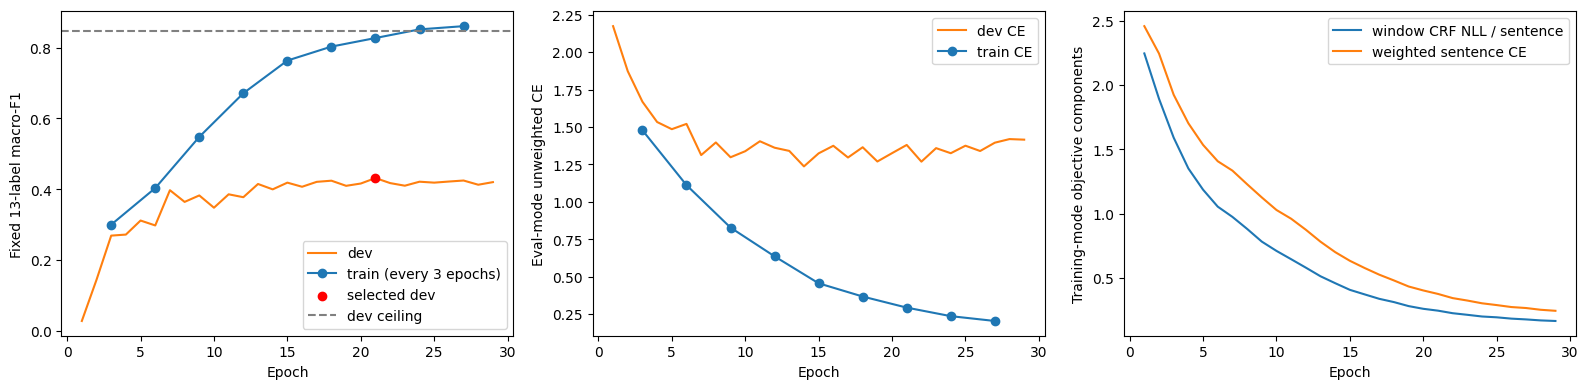

DIAGNOSTICS: /kaggle/working/cs781_phase3/runs/encdec_rr_lora_001_diagnostics.zip
RESUMABLE BACKUP: /kaggle/working/cs781_phase3/runs/encdec_rr_lora_001_backup.zip
SUBMISSION: /kaggle/working/cs781_phase3/runs/encdec_rr_lora_001_submission.zip
SELECTED TRAINABLE CHECKPOINT: /kaggle/working/cs781_phase3/runs/encdec_rr_lora_001/best_rr.pt
Original Phase 1 dependency SHA256: 2a2d34a8df48bce7b6ab8132ea011803e2d044df8eaacde110046653b85516a5


In [20]:
import matplotlib.pyplot as plt

history=read_json(RUN_DIR/'history.json')
epoch_rows=[r for r in history if r['kind']=='epoch']
if epoch_rows:
    dev_x=[r['epoch'] for r in epoch_rows]
    train_rows=[r for r in epoch_rows if r['train'] is not None]
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    axes[0].plot(dev_x,[r['dev']['combined']['macro_f1'] for r in epoch_rows],label='dev',color='tab:orange')
    axes[1].plot(dev_x,[r['dev']['losses']['unweighted_sentence_ce'] for r in epoch_rows],label='dev CE',color='tab:orange')
    if train_rows:
        train_x=[r['epoch'] for r in train_rows]
        axes[0].plot(train_x,[r['train']['combined']['macro_f1'] for r in train_rows],marker='o',label='train (every 3 epochs)')
        axes[1].plot(train_x,[r['train']['losses']['unweighted_sentence_ce'] for r in train_rows],marker='o',label='train CE')
    axes[0].scatter([run_summary['best_epoch']],[run_summary['selected_dev']['combined']['macro_f1']],color='red',label='selected dev',zorder=5)
    axes[0].axhline(11/13,linestyle='--',color='gray',label='dev ceiling')
    axes[2].plot(dev_x,[r['window_crf_nll_per_sentence'] for r in epoch_rows],label='window CRF NLL / sentence')
    axes[2].plot(dev_x,[r['weighted_sentence_ce'] for r in epoch_rows],label='weighted sentence CE')
    for axis,ylabel in zip(axes,('Fixed 13-label macro-F1','Eval-mode unweighted CE','Training-mode objective components')):
        axis.set(xlabel='Epoch',ylabel=ylabel)
        axis.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR/'training_curves.png',dpi=150)
    plt.show()
    pd.DataFrame([{'epoch':r['epoch'],'dev_macro_f1':r['dev']['combined']['macro_f1'],
        'train_macro_f1':r['train']['combined']['macro_f1'] if r['train'] is not None else None,
        'dev_ce':r['dev']['losses']['unweighted_sentence_ce'],
        'window_crf_nll_per_sentence':r['window_crf_nll_per_sentence'],'weighted_sentence_ce':r['weighted_sentence_ce']}
        for r in epoch_rows]).to_csv(RUN_DIR/'epoch_history.csv',index=False)

diagnostics_zip,backup_zip=save_diagnostics(RUN_DIR)
print('DIAGNOSTICS:',diagnostics_zip)
print('RESUMABLE BACKUP:',backup_zip)
print('SUBMISSION:',run_summary['submission_zip'])
print('SELECTED TRAINABLE CHECKPOINT:',RUN_DIR/'best_rr.pt')
print('Original Phase 1 dependency SHA256:',checkpoint_sha)

## References

- Additive low-rank adapters. [LoRA](https://arxiv.org/abs/2106.09685)
- Context-aware legal sentence classification. [Semantic Segmentation of Legal Documents via Rhetorical Roles](https://aclanthology.org/2022.nllp-1.13/)
- Learned sequence scores and Viterbi decoding. [Neural Architectures for Named Entity Recognition](https://aclanthology.org/N16-1030/)
